# Investigating Drought Condition Trends Across the Western United States 
## Climate/Space 323: Final Project
### Members
* Daniel He, Maydine Bellot, Sarah Tahboub

## Introduction
&emsp;Our focus is on examining drought in Western United States and researching the causes and impacts of drought in said region. We will examine high temperatures and precipitation levels alongside the Palmer Drought Severity Index or PDSI. We plan to find the correlation between these factors and the droughts recorded in the west. 

&emsp;The Western United States is experiencing widespread drought conditions. In 2025, 65.5% of the region is in drought, with 14% in extreme or exceptional drought according to the US Drought Monitor [1]. Drought devastates communities in a variety of ways including damage to agriculture, shortages and restrictions of water, poor soil quality, increase in wildfires, and the destruction of ecosystems present in the area [2]. Severe droughts disproportionately impact the rural, low-income communities including the Indigenous populations in the area [3]. Higher temperatures, brought about by climate change, will only worsen the drought conditions in the years to come. 

&emsp;To analyze droughts over the past years, we will utilize the Palmer Drought Severity Index (PDSI). PDSI is an accessible data set that estimates relative dryness and has proven to be efficient in quantifying long term drought. The standardized index utilizes temperature data and a physical water balance model, therefore demonstrating shifting levels of evapotranspiration that may potentially occur with climate change. [4] 

&emsp;In recent years, NOAA has conducted a study that finds that heat is the driving cause of drought - not necessarily the lack of precipitation as previously observed. During the 2020-22 drought, evaporation accounted for 61% of the drought’s severity, whereas lack of precipitation only accounted for 39%. [5] Our group hopes to analyze these changes to drought through our data sets from 2000-2025 of high temperatures, evaporation and precipitation levels, and the PDSI itself. In doing so, we can see if our results verify the NOAA study, reinforcing the idea that heat is a greater contributor to drought than lack of precipitation. 

## Data
The following datasets were used:
* ERA5 post-processed daily statistics on single levels from 1940 to present [6]
  * Accessed from Copernicus’ Climate Data Store
  * Contains gridded meteorological data from renanalysis 
  * Sampling frequency of 1 sample per day
  * The variables we gathered data on were:
    * Evaporation (units in m)
    * Total Precipitation (units in m)
    * 2m Temperature (Surface Temperature, units in K)
  * We extracted a subregion defined by 25.06° to 49.40° N and -124.77° to -67.05°W (Contiguous U.S.)
  * Contains data from 1940 to present (we will be looking at 2000–2025)
  * Link to access dataset: https://cds.climate.copernicus.eu/datasets/derived-era5-single-levels-daily-statistics?tab=download
  * Link to access documentation: https://confluence.ecmwf.int/display/CKB/ERA5+family+post-processed+daily+statistics+documentation

* U.S. Gridded Palmer Drought Severity Index (PDSI) from gridMET [7]
  * Accessed from the National Integrated Drought Information System’s website
  * Sampling frequency of 1 sample per 5 days
  * Units in PDSI, which is defined along a scale of -10 (dry) to 10 (wet)
  * Dataset covers the Contiguous U.S.
  * Contains data from 1980 to present (we will be looking at 2000-2025)
  * Link to access dataset and documentation: https://www.drought.gov/data-maps-tools/us-gridded-palmer-drought-severity-index-pdsi-gridmet

* Oceanic Niño Index [8]
  * Accessed from NOAA
  * Rolling 3-month average temperature anomaly in the surface waters of the east-central tropical Pacific [9]
  * Sampling frequency of 1 sample per month
  * Units in ONI, in which values of +0.5 or higher indicate El Niño. Values of -0.5 or lower indicate La Niña.
  * Link to access dataset: https://www.cpc.ncep.noaa.gov/data/indices/
  * Link to access documentation: https://www.climate.gov/news-features/understanding-climate/climate-variability-oceanic-nino-index

----

## Approach and Results

**Import Libraries:**

We made use of the following libraries within our code. The last three libraries are notable, as they have not been used in previous labs. Further discussion on these libraries will be found within the sections that employ said libraries.

In [7]:
%ls

2000evap.nc
2001evap.nc
2002evap.nc
2003evap.nc
2004evap.nc
2005evap.nc
2006evap.nc
2007evap.nc
2008evap.nc
2009evap.nc
2010evap.nc
2011evap.nc
2012evap.nc
2013evap.nc
2014evap.nc
2015evap.nc
2016evap.nc
2017evap.nc
2018evap.nc
2019evap.nc
2020evap.nc
Evaporation/
Investigating Drought Condition Trends Across the Western United States 323 Final Project.ipynb


In [2]:
# Import libaries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.fftpack import fft, fftfreq, ifft
from scipy.signal import spectrogram
import netCDF4 # Used during the cropping process.
import xarray as xr # To read in netcdf.
import xesmf as xe # For regridding.
import dask.array as da # For optimization.

%matplotlib inline
plt.style.use('default') # Will be changed later.

## Part 1: Data Processing
When gathering data from Copernicus’ ERA5 datasets, it is only possible to gather 1 year of data for 1 variable at a time. Performing data analysis in this format is difficult and unoptimized. Thus, we need to combine the datasets for each specific variable into one large netCDF file each. Additionally, we decided that the Western U.S. was far too varied in its climate to be considered one region for the scope of our analysis. As such, we cropped our data to be within the Southwest U.S., which we defined as the states of Arizona, California, Colorado, Nevada, New Mexico, and Utah. 

The following code accomplishes this, and was guided by an Medium article by Neeti Nayak [10]. These code cells only need to be and should only be ran once. This is also where we introduce the xarray library, which is what we used to handle the netCDF data. When using xarray, netCDF files are stored as xarray Datasets, which is itself a container of multiple different DataArrays. Many different functions of xarray can only be ran on DataArrays.

In [9]:
# Process the evaporation data.
# Crop the data, then place into a new netcdf file.
# NOTE! Change the file strings as necessary.
years = list(range(2000, 2020))
#originally 0,26
for y in years:
    with xr.open_dataset(f'{y:02}evap.nc') as ds:
        cropped = ds.sel(latitude=slice(42.06, 30.9), longitude=slice(-124.50, -102))
        cropped.to_netcdf(f'evapCropped{y:02}.nc')

# Open all the files as one xarray.
# The star replaces the year of the filename.
ds = xr.open_mfdataset('evapCropped*.nc')

# Save the combined files into a single netcdf. 
# Change file name as necessary.
ds.to_netcdf('evap_combined.nc')

In [10]:
# Process the precipitation data.
# Crop the data, then place into a new netcdf file.
# NOTE! Change the file strings as necessary.
years = list(range(0, 26))
for y in years:
    with xr.open_dataset(f'precip{y:02}.nc') as ds:
        cropped = ds.sel(latitude=slice(42.06, 30.9), longitude=slice(-124.50, -102))
        cropped.to_netcdf(f'preCropped{y:02}.nc')

# Open all the files as one xarray.
# The star replaces the year of the filename.
ds = xr.open_mfdataset('preCropped*.nc')

# Save the combined files into a single netcdf. 
# Change file name as necessary.
ds.to_netcdf('precip_combined.nc')

FileNotFoundError: [Errno 2] No such file or directory: '/Users/maydine/Examining Drought Trends.../precip00.nc'

In [ ]:
# Process the surface temperature data.
# Crop the data, then place into a new netcdf file.
# NOTE! Change the file strings as necessary.
years = list(range(0, 26))
for y in years:
    with xr.open_dataset(f'temp{y:02}.nc') as ds:
        cropped = ds.sel(latitude=slice(42.06, 30.9), longitude=slice(-124.50, -102))
        cropped.to_netcdf(f'tempCropped{y:02}.nc')

# Open all the files as one xarray.
# The star replaces the year of the filename.
ds = xr.open_mfdataset('tempCropped*.nc')

# Save the combined files into a single netcdf. 
# Change file name as necessary.
ds.to_netcdf('temp_combined.nc')

To help us understand the data that we're working with, we can make some initial plots of certain days of data. 

In [7]:
# Open the xarray Datasets.
ds_pdsi = xr.open_dataset('pdsiFullSet.nc')
ds_temp = xr.open_dataset('temp_combined.nc')
ds_evap = xr.open_dataset('evap_combined.nc')
ds_prec = xr.open_dataset('precip_combined.nc')

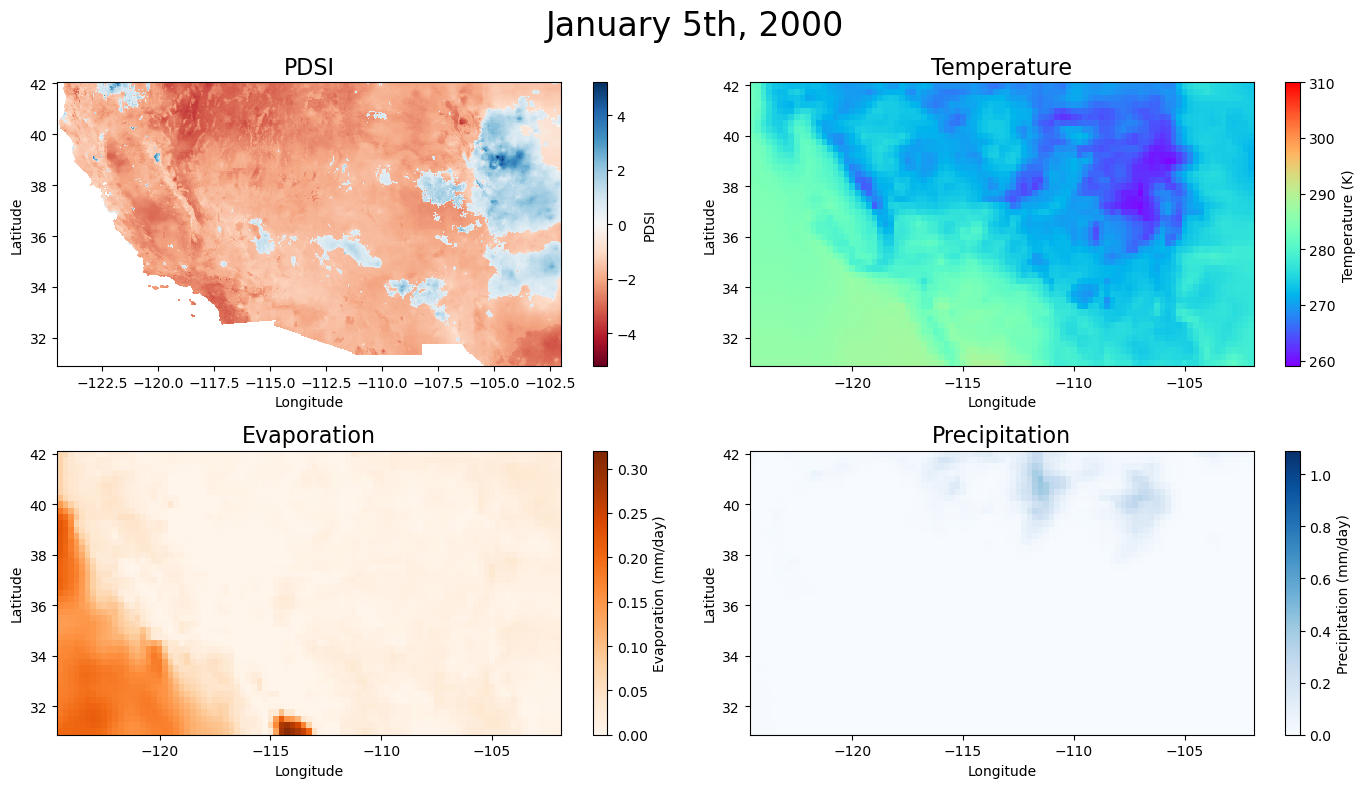

In [23]:
# Select a day of data (Janurary 5th, 2000).
# This code converts converts each dataset into an xarray DataArray that can be plotted.
cropped = ds_pdsi.sel(lat=slice(42.06, 30.9), lon=slice(-124.50, -102))
pdsiDay = cropped["daily_mean_palmer_drought_severity_index"].sel(day='2000-01-05')
tempDay = ds_temp["t2m"].sel(valid_time='2000-01-05')
evapDay = ds_evap["e"].sel(valid_time='2000-01-05')
evapDay = np.abs(evapDay * 1000) # Convert to mm/day
precDay = ds_prec["tp"].sel(valid_time='2000-01-05')
precDay = precDay * 1000 # Convert to mm/day

# Create a figure and axis.
fig, axes = plt.subplots(2, 2, figsize = [14,8])

# Plot the data.
pdsiDay.plot(cmap="RdBu", ax=axes[0, 0], vmin = -5.2, vmax = 5.2,
             cbar_kwargs={'label': 'PDSI'})
tempDay.plot(cmap="rainbow", ax=axes[0, 1], vmin = 259, vmax = 310,
             cbar_kwargs={'label': 'Temperature (K)'})
evapDay.plot(cmap="Oranges", ax=axes[1, 0], vmin = 0, vmax = 0.32,
             cbar_kwargs={'label': 'Evaporation (mm/day)'})
precDay.plot(cmap="Blues", ax=axes[1, 1], vmin = 0, vmax = 1.09,
             cbar_kwargs={'label': 'Precipitation (mm/day)'})

# Label the plots.
axes[0, 0].set_title('PDSI', fontsize=16)
axes[0, 0].set_xlabel('Longitude')
axes[0, 0].set_ylabel('Latitude')
axes[0, 1].set_title('Temperature', fontsize=16)
axes[0, 1].set_xlabel('Longitude')
axes[0, 1].set_ylabel('Latitude')
axes[1, 0].set_title('Evaporation', fontsize=16)
axes[1, 0].set_xlabel('Longitude')
axes[1, 0].set_ylabel('Latitude')
axes[1, 1].set_title('Precipitation', fontsize=16)
axes[1, 1].set_xlabel('Longitude')
axes[1, 1].set_ylabel('Latitude')

fig.suptitle('January 5th, 2000', fontsize=24)
fig.tight_layout()

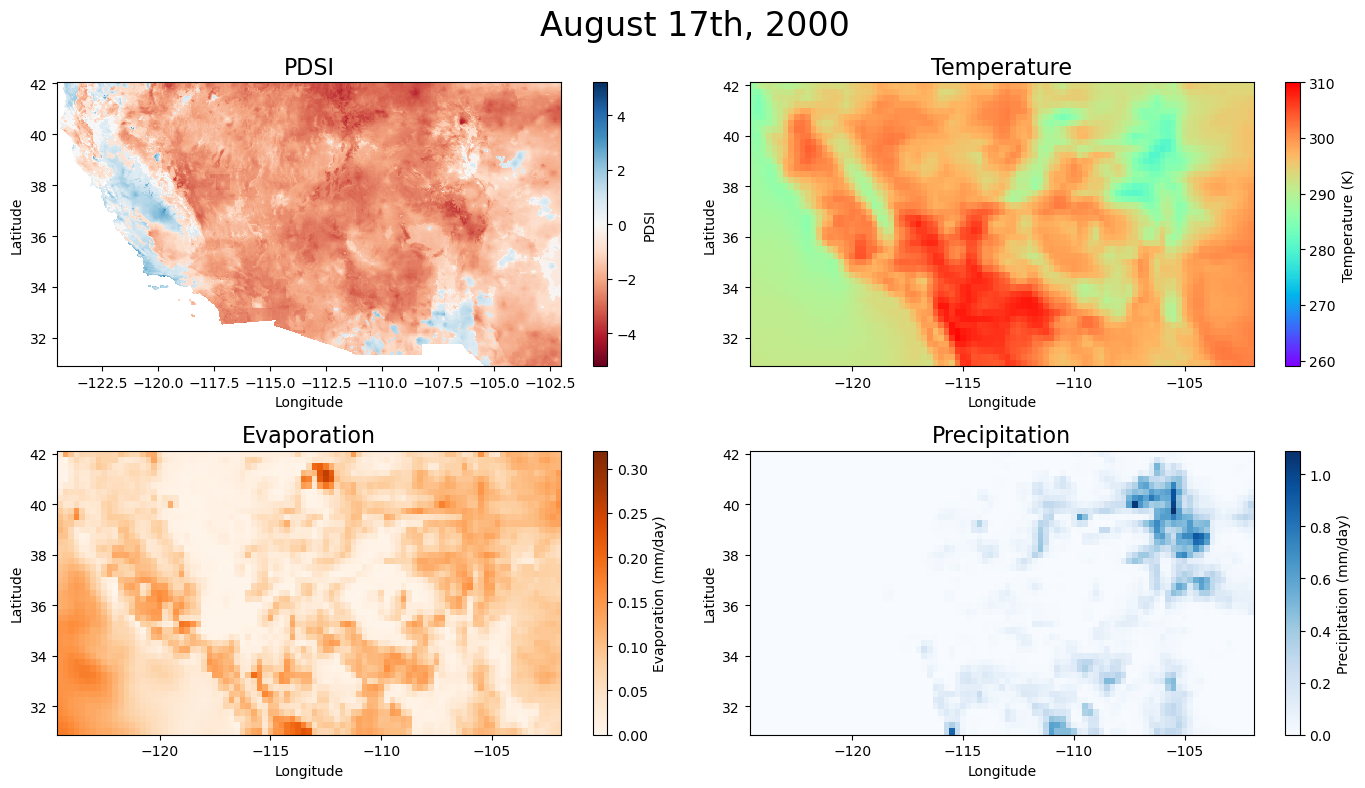

In [5]:
# Select a day of data (August 17th, 2000).
# This code converts converts each dataset into an xarray DataArray that can be plotted.
cropped = ds_pdsi.sel(lat=slice(42.06, 30.9), lon=slice(-124.50, -102))
pdsiDay = cropped["daily_mean_palmer_drought_severity_index"].sel(day='2000-08-17')
tempDay = ds_temp["t2m"].sel(valid_time='2000-08-17')
evapDay = ds_evap["e"].sel(valid_time='2000-08-17')
evapDay = np.abs(evapDay * 1000) # Convert to mm/day
precDay = ds_prec["tp"].sel(valid_time='2000-08-17')
precDay = precDay * 1000 # Convert to mm/day

# Create a figure and axis.
fig, axes = plt.subplots(2, 2, figsize = [14,8])

# Plot the data.
pdsiDay.plot(cmap="RdBu", ax=axes[0, 0], vmin = -5.2, vmax = 5.2,
             cbar_kwargs={'label': 'PDSI'})
tempDay.plot(cmap="rainbow", ax=axes[0, 1], vmin = 259, vmax = 310,
             cbar_kwargs={'label': 'Temperature (K)'})
evapDay.plot(cmap="Oranges", ax=axes[1, 0], vmin = 0, vmax = 0.32,
             cbar_kwargs={'label': 'Evaporation (mm/day)'})
precDay.plot(cmap="Blues", ax=axes[1, 1], vmin = 0, vmax = 1.09,
             cbar_kwargs={'label': 'Precipitation (mm/day)'})

# Label the plots.
axes[0, 0].set_title('PDSI', fontsize=16)
axes[0, 0].set_xlabel('Longitude')
axes[0, 0].set_ylabel('Latitude')
axes[0, 1].set_title('Temperature', fontsize=16)
axes[0, 1].set_xlabel('Longitude')
axes[0, 1].set_ylabel('Latitude')
axes[1, 0].set_title('Evaporation', fontsize=16)
axes[1, 0].set_xlabel('Longitude')
axes[1, 0].set_ylabel('Latitude')
axes[1, 1].set_title('Precipitation', fontsize=16)
axes[1, 1].set_xlabel('Longitude')
axes[1, 1].set_ylabel('Latitude')

fig.suptitle('August 17th, 2000', fontsize=24)
fig.tight_layout()

Our initial plots highlight some interesting findings. First, we can verify that our temperature data is likely correct given that land surface temperatures were much higher in August than in Janurary. Additionally, we found that the majority of the region experienced dry conditions on both days, as indicated by the consistently negative PDSI values. Another notable finding was how blank the precipitation map was, indicating a lack of rainfall in the Southwest U.S.

Now that we’ve got the data into their respective netCDF files, we can extract some useful information from them. Later in Part 2, we'll need to perform trendline analysis and FFT's on our data, which would be difficult to perform on gridded data. As such, we'll find the mean of each day of data for a given variable, then save it into a CSV file. This code makes use of XArray's mean function, which can find the mean of a DataArray along some dimension [11]. The following code cells only need to be and should only be ran once.

In [ ]:
# Process the evaporation data.
# Select the evaporation variable. 
e_var = ds_evap['e'][:]

# Extract the mean evaporation on each day of data.
mean_e = e_var.mean(dim=['latitude', 'longitude']) # xarray DataArray

# Extract the times and values from the DataArray.
times = mean_e['valid_time']
values = mean_e.values

# Save the data into a CSV file.
data = np.column_stack((times.astype(str), values))
np.savetxt('mean_e_values.csv', data, delimiter=',', header='time, mean_e', fmt = '%s')

In [9]:
# Process the precipiation data.
# Select the precipiation variable. 
p_var = ds_prec['tp'][:]

# Extract the mean precipitation on each day of data.
mean_p = p_var.mean(dim=['latitude', 'longitude']) # xarray DataArray

# Extract the times and values from the DataArray.
times = mean_p['valid_time']
values = mean_p.values

# Save the data into a CSV file.
data = np.column_stack((times.astype(str), values))
np.savetxt('mean_precip_timeseries.csv', data, delimiter=',', header='time, mean_precip', fmt = '%s')

In [36]:
# Process the temperature data.
# Select the temperature variable. 
t_var = ds_temp['t2m'][:]

# Extract the mean temperature on each day of data.
mean_t = t_var.mean(dim=['latitude', 'longitude']) # xarray DataArray

# Extract the times and values from the DataArray.
times = mean_t['valid_time']
values = mean_t.values

# Save the data into a CSV file.
data = np.column_stack((times.astype(str), values))
np.savetxt('mean_temp_timeseries.csv', data, delimiter=',', header='time, mean_temp', fmt = '%s')

In [ ]:
# Process the PDSI data.
# Select the PDSI variable. 
t_var = ds_temp['daily_mean_palmer_drought_severity_index'][:]

# Extract the mean PDSI on each day of data.
mean_t = t_var.mean(dim=['lat', 'lon']) # xarray DataArray

# Extract the times and values from the DataArray.
times = mean_t['day']
values = mean_t.values

# Save the data into a CSV file.
data = np.column_stack((times.astype(str), values))
np.savetxt('mean_pdsi_timeseries.csv', data, delimiter=',', header='time, mean_pdsi', fmt = '%s')

## Part 2: Data Analysis
### Question 1

What are the overall trends in PDSI, evaporation, precipitation, and temperature? Can we examine these trends using time series plots and low-pass filters?

We start by reading in the CSV files created in the previous part, which contain the mean values for our chosen region of the Western United States. We will read in the PDSI, evaporation, precipitation, and temperature CSV files. Then we will save the data into variables, and convert the time measurements into datetime arrays. We will also create a new array of the precipitation - evaporation, which is representative of the water balance, or the net flux of water. Note that the original evaporation file measured evaporation as a purely negative value. 

In [37]:
# Read in the CSV files.
data_pdsi = np.genfromtxt('mean_pdsi_timeseries.csv', skip_header = 1, dtype=None, 
                          delimiter=',', encoding='utf-8', names=('time', 'pdsi'))
data_e = np.genfromtxt('mean_e_values.csv', skip_header = 1, dtype=None, 
                       delimiter=',', encoding='utf-8', names=('time', 'evap'))
data_p = np.genfromtxt('mean_precip_timeseries.csv', skip_header = 1, dtype=None, 
                       delimiter=',', encoding='utf-8', names=('time', 'precip'))
data_t = np.genfromtxt('mean_temp_timeseries.csv', skip_header=1, dtype=None, 
                       delimiter=',', encoding='utf-8', names=('time','temp'))

# Save the data into arrays.
pdsi = data_pdsi['pdsi']
time_pdsi = data_pdsi['time']
dt_pdsi = pd.to_datetime(time_pdsi) #converting time into datetime array

temp = data_t['temp']
precip = data_p['precip'] * 1000 #converting into mm/day
evap = data_e['evap'] * (-1000) #converting into mm/day (initially evaporation is negative)

# All ERA5 files have the same time period, so we'll just use the same time array
time = data_p['time']
dt_pe = pd.to_datetime(time) #converting time into datetime array

net_pe = (precip-evap) # P-E, still units of mm/day (evaporation is negative


Then, we will create time series plots using the saved variables. We will do this for PDSI, temperature, precipitation, evaporation, and precipitation-evaporation.

In [84]:
# Change the plot style back to fivethirtyeight.
plt.style.use('fivethirtyeight')

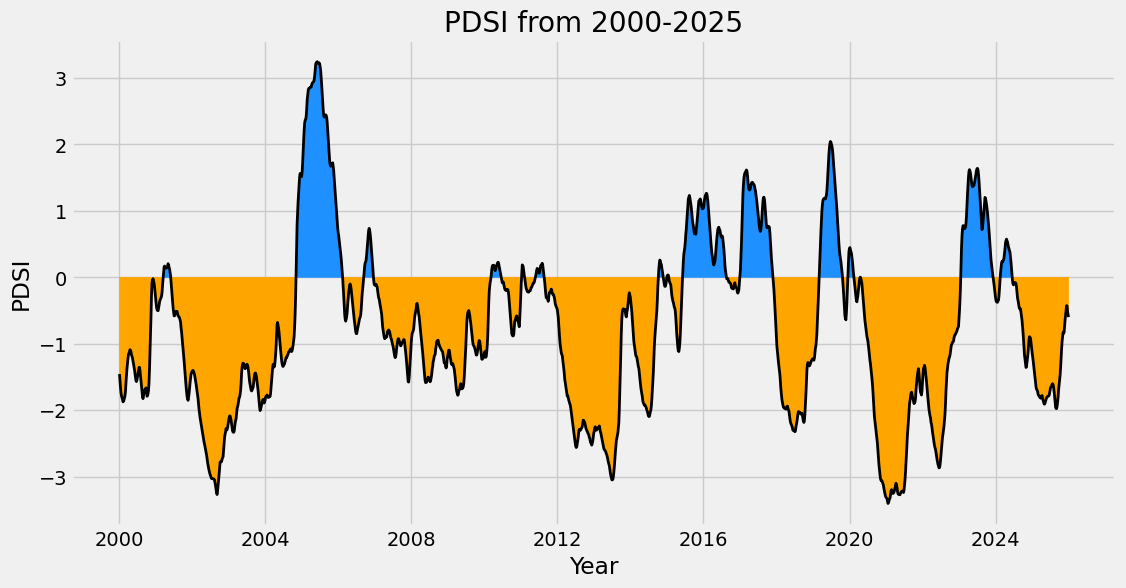

In [39]:
# Plotting PDSI
plt.figure(figsize=(12,6))
plt.plot(dt_pdsi, pdsi, color='black', lw=2)
plt.title('PDSI from 2000-2025')
plt.xlabel('Year')
plt.ylabel('PDSI')

# Fancy fill-in function to make the negative values orange and positive values blue.
pos = np.where(pdsi > 0, pdsi, np.nan)
neg = np.where(pdsi < 0, pdsi, np.nan)
plt.fill_between(pd.to_datetime(time_pdsi), 0, pos, color='dodgerblue')
plt.fill_between(pd.to_datetime(time_pdsi), 0, neg, color='orange')


From this plot we see that the Southwest U.S. is consistently in a period of dryness, with only a few small and short pockets of wet periods. This is to be expected, as the Southwest is known to be a relatively drier region. The periodicity that drives this change in PDSI appears to be quite long, possibly lasting around a few years. 

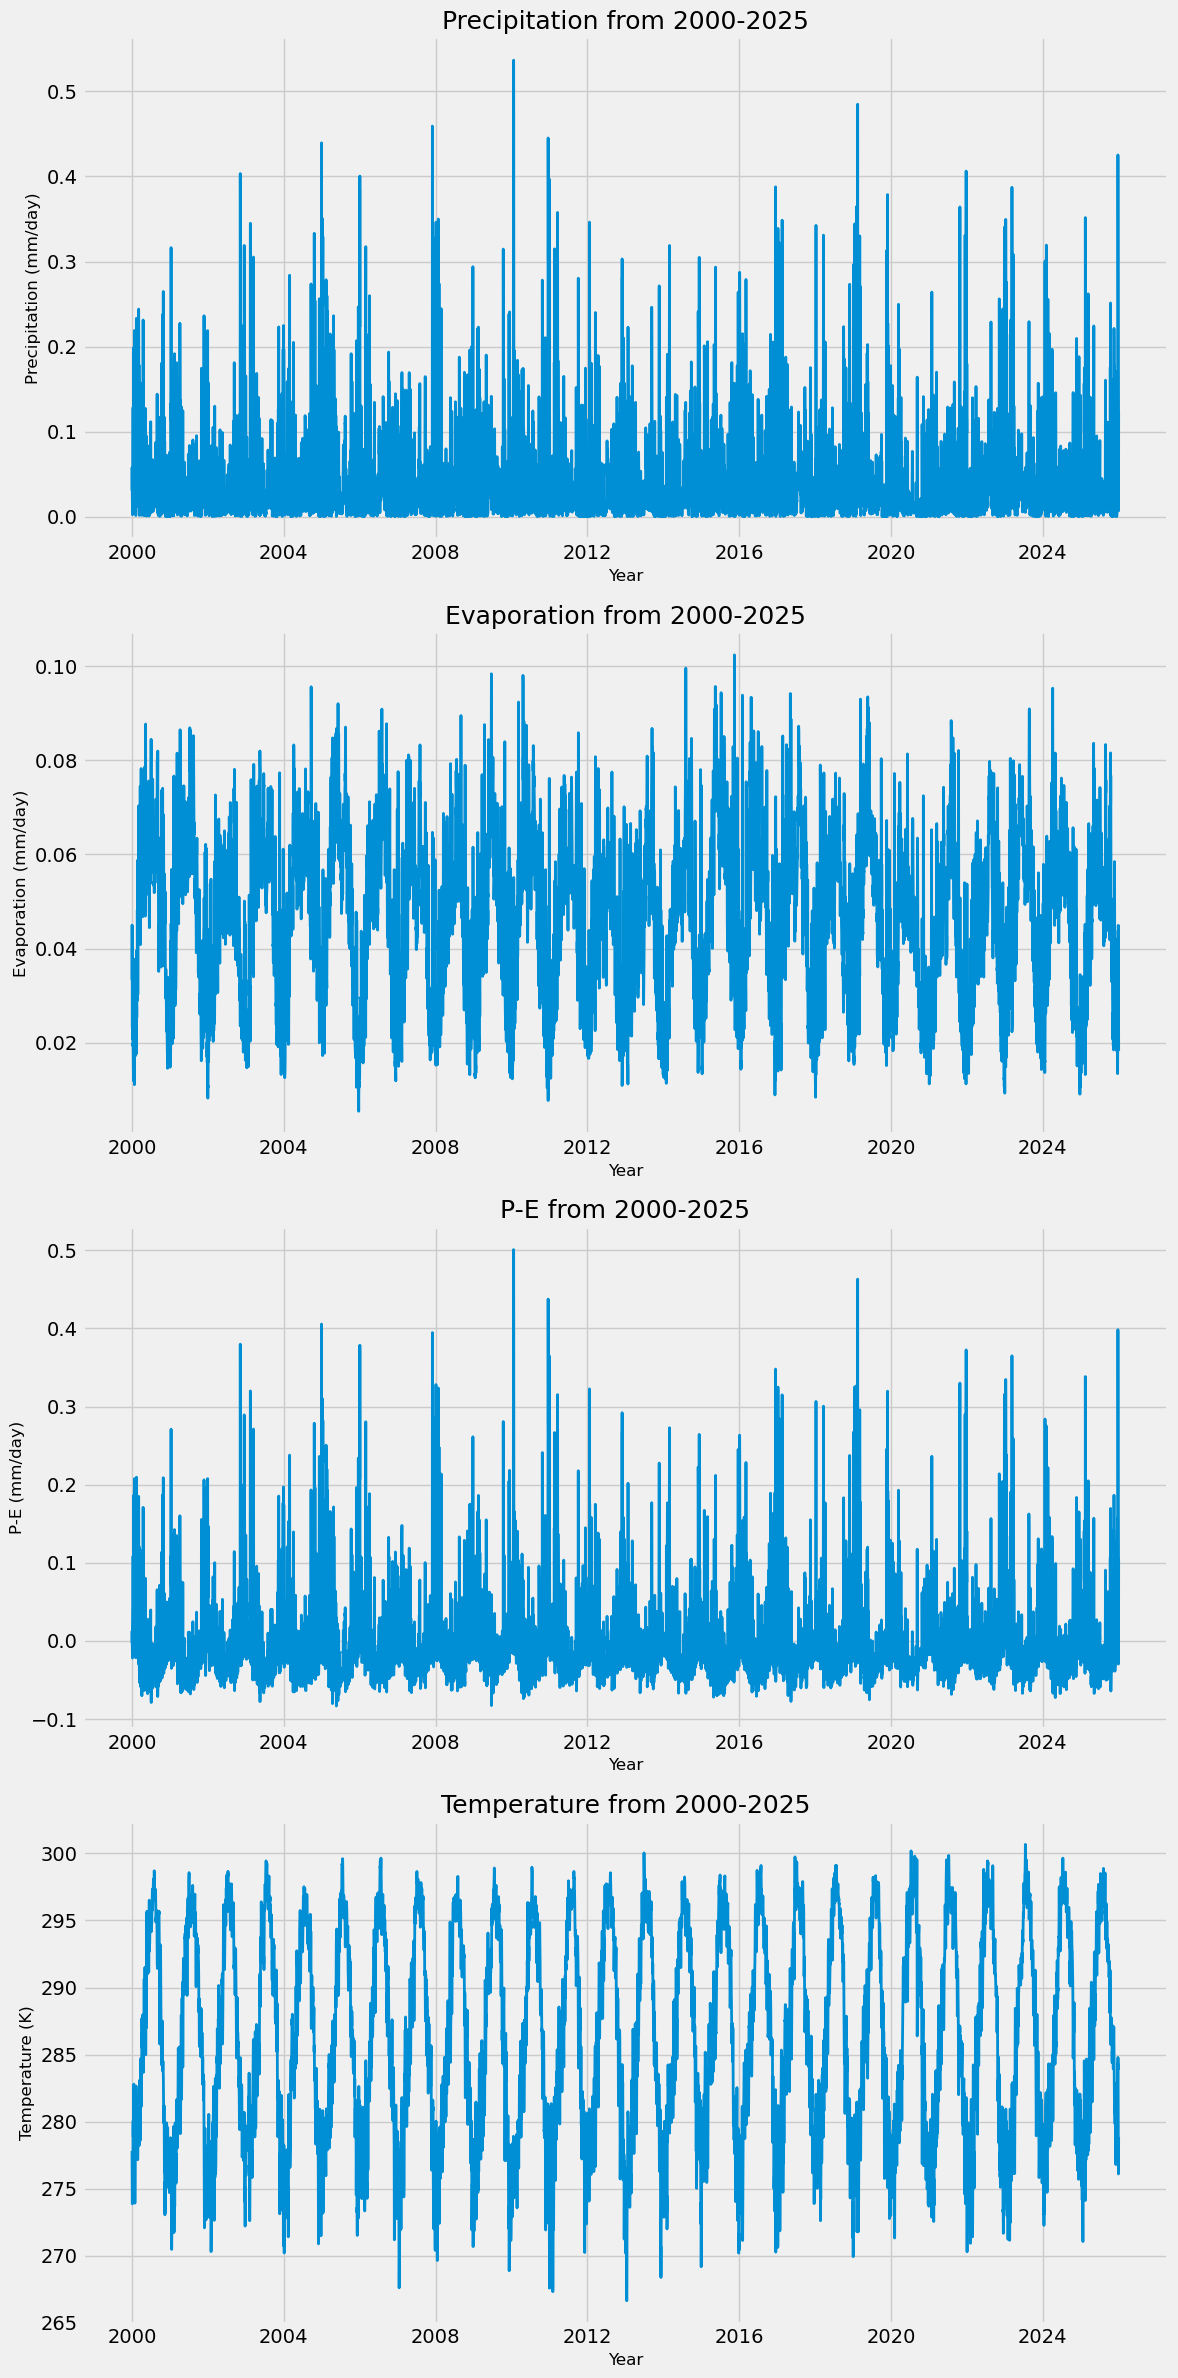

In [43]:
# Creating figure and plotting temperature, precipitation, evaporation, and P-E over time.
fig, ax = plt.subplots(4,1, figsize=(12,24))

# Precip
ax[0].plot(dt_pe, precip, lw=2)
ax[0].set_title('Precipitation from 2000-2025', fontsize=18)
ax[0].set_xlabel('Year', fontsize=12)
ax[0].set_ylabel('Precipitation (mm/day)', fontsize=12)

# Evap
ax[1].plot(dt_pe, evap, lw=2)
ax[1].set_title('Evaporation from 2000-2025', fontsize=18)
ax[1].set_xlabel('Year', fontsize=12)
ax[1].set_ylabel('Evaporation (mm/day)', fontsize=12)

# P-E
ax[2].plot(dt_pe, net_pe, lw=2)
ax[2].set_title('P-E from 2000-2025', fontsize=18)
ax[2].set_xlabel('Year', fontsize=12)
ax[2].set_ylabel('P-E (mm/day)', fontsize=12)

# Temperature
ax[3].plot(dt_pe, temp, lw=2)
ax[3].set_title('Temperature from 2000-2025', fontsize=18)
ax[3].set_xlabel('Year', fontsize=12)
ax[3].set_ylabel('Temperature (K)', fontsize=12)

# Fixing formatting
fig.tight_layout()


From these plots, we can see that there is consistent variation in the temperature, precipitation, evaporation, and P-E plots. This variation makes it difficult to assess overall trends for this large timescale. The variation we are seeing in these plots is due to seasonal variations. In order to better understand the overall trends of this data, we will be applying a low pass filter to our data. We will do this by taking the fft of each dataset, and filtering out frequencies that fall above our decided low frequency. We decided on a cutoff of 0.9 cycles per year, the reasoning behind which will be discussed in question 2. Then we put our lowpass filtered fft back into the time domain to assess the low pass filtered data. We will perform a linear fit for each of these low pass filtered datasets to assess the overall trends for this time period. We will do this for precipitation, evaporation, P-E, and temperature. 

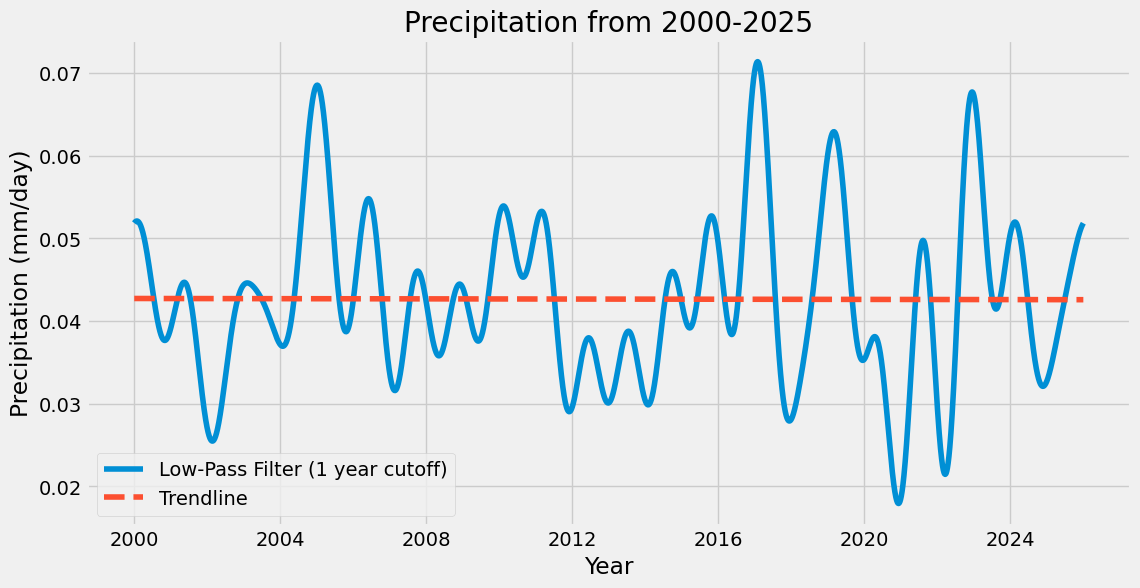

In [ ]:
#fft for precipitation
sr_y = 1/365.25 #sampling rate in 1/years
N = precip.size # num of measurements
precip_fft = fft(precip) #not normalized yet, fft
freqs_y = fftfreq(N, sr_y)
precip_amps = np.abs(precip_fft) #amplitude
mask = freqs_y > 0 #only positive freqs, not including the mean

#lowpass filter
f_low = 0.9 # less than the dominant freq rn bcs its a year
lp_mask = np.abs(freqs_y) > f_low
fft_lp = precip_fft.copy()
fft_lp[lp_mask] = 0
pos_mask = freqs_y > 0

#back into the time domain :O
precip_lowpass = np.real(ifft(fft_lp))

#linear fit
coeff = np.polyfit(pd.to_numeric(dt_pe), precip_lowpass,1)
m, c = coeff
y_fit_lowpass = m*pd.to_numeric(dt_pe) + c # equation for the linear fit

# figure plotting lowpass filtered data
fig, ax = plt.subplots(1,1,figsize=(12,6))

#lowpass filtered data with trendline
ax.plot(dt_pe, precip_lowpass,label='Low-Pass Filter (1 year cutoff)') # plotting lowpass filtered data
ax.plot(dt_pe, y_fit_lowpass, label='Trendline', ls='--') #plotting trendline for lowpass filtere data
ax.set_xlabel('Year')
ax.set_title('Precipitation from 2000-2025')
ax.set_ylabel('Precipitation (mm/day)')
ax.legend()

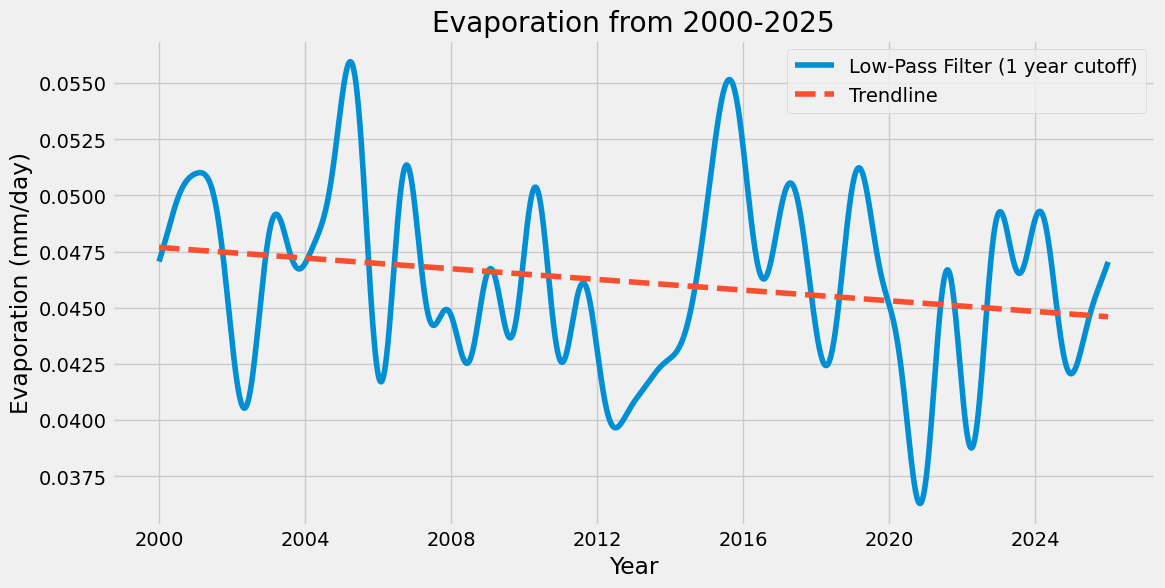

In [74]:
#fft for evap
sr_y = 1/365.25 #sampling rate in 1/years
N = evap.size # num of measurements
evap_fft = fft(evap) #not normalized yet, fft
freqs_y = fftfreq(N, sr_y)
evap_amps = np.abs(evap_fft) #amplitude
mask = freqs_y > 0 #only positive freqs, not including the mean

#lowpass filter for evap
f_low = 0.9 # less than the dominant freq rn bcs its a year
lp_mask = np.abs(freqs_y) > f_low
fft_lp = evap_fft.copy()
fft_lp[lp_mask] = 0
pos_mask = freqs_y > 0

#back into the time domain :O
evap_lowpass = np.real(ifft(fft_lp))

#linear fit
coeff = np.polyfit(pd.to_numeric(dt_pe), evap_lowpass,1)
m, c = coeff
y_fit_lowpass = m*pd.to_numeric(dt_pe) + c #equation for the linear fit

#figure plotting lowpass filtered data
fig, ax = plt.subplots(1,1,figsize=(12,6))

#lowpass filtered data with trendline
ax.plot(dt_pe, evap_lowpass,label='Low-Pass Filter (1 year cutoff)') # plotting lowpass filtered data
ax.plot(dt_pe, y_fit_lowpass, label='Trendline', ls='--') #plotting trendline for lowpass filtered data
ax.set_xlabel('Year')
ax.set_title('Evaporation from 2000-2025')
ax.set_ylabel('Evaporation (mm/day)')
ax.legend()

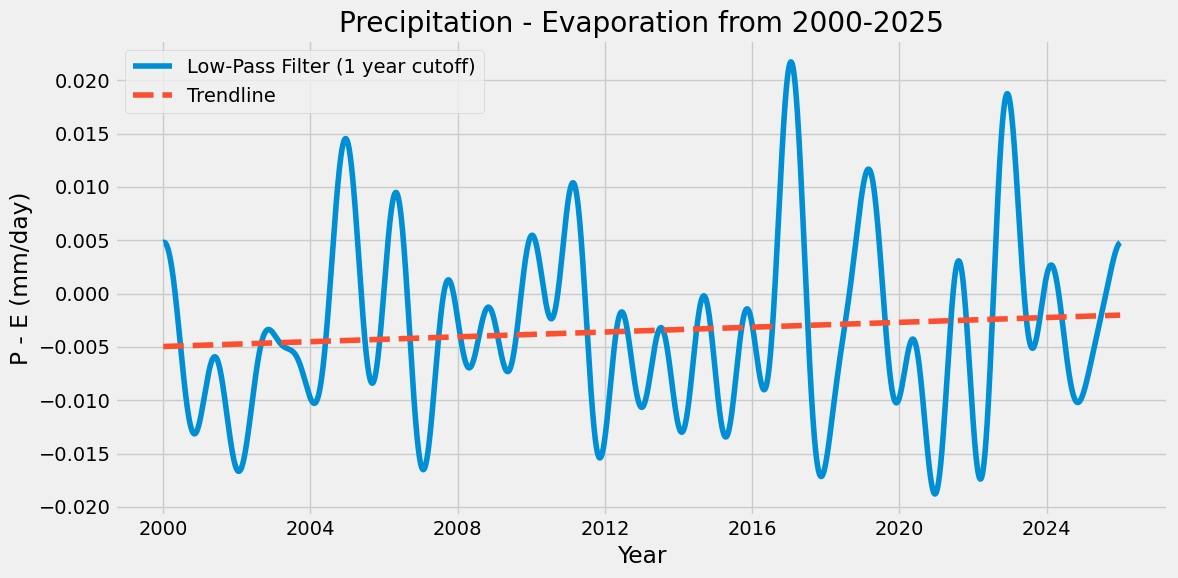

In [77]:
#fft for net precip/evap
sr_y = 1/365.25 #sampling rate in 1/years
N = net_pe.size # num of measurements
pe_fft = fft(net_pe) #not normalized yet, fft
freqs_y = fftfreq(N, sr_y) #frequency in cycles/year
pe_amps = np.abs(pe_fft) #amplitude
mask = freqs_y > 0 # making mask for only frequencies above 0 (not including the mean, same as previous fft for pdsi)

#lowpass filter for evap/precip
f_low = 0.9 # less than the dominant freq rn bcs its a year (0.9 is close enough bcs actually frequency is 0.999... so we're just rounding to make things simpler)
lp_mask = np.abs(freqs_y) > f_low #creating a mask thats true for all frequencies greater than 0.9
fft_lp = pe_fft.copy() #copying the original fft
fft_lp[lp_mask] = 0 #making all frequencies greater than 0.9 0 and only letting the lower frequencies stay/pass (low-PASS filter :O)

#back to the time domain! + (linear fit time)
pe_lowpass = np.real(ifft(fft_lp)) #using inverse fft to put data back into the time domain

#linear fit time
coeff = np.polyfit(pd.to_numeric(dt_pe), pe_lowpass,1)
m, c = coeff
y_fit_lowpass = m*pd.to_numeric(dt_pe) + c #equaiton for the linear fit

#creating figure for lowpass filterd data with trendline
fig, ax = plt.subplots(1,1,figsize=(12,6))

#lowpass filtered data with trendline
ax.plot(dt_pe, pe_lowpass,label='Low-Pass Filter (1 year cutoff)') # plotting lowpass filtered data
ax.plot(dt_pe, y_fit_lowpass, label='Trendline', ls='--') #plotting trendline for lowpass filtere data
ax.set_xlabel('Year')
ax.set_title('Precipitation - Evaporation from 2000-2025')
ax.set_ylabel('P - E (mm/day)')
ax.legend()

plt.tight_layout()


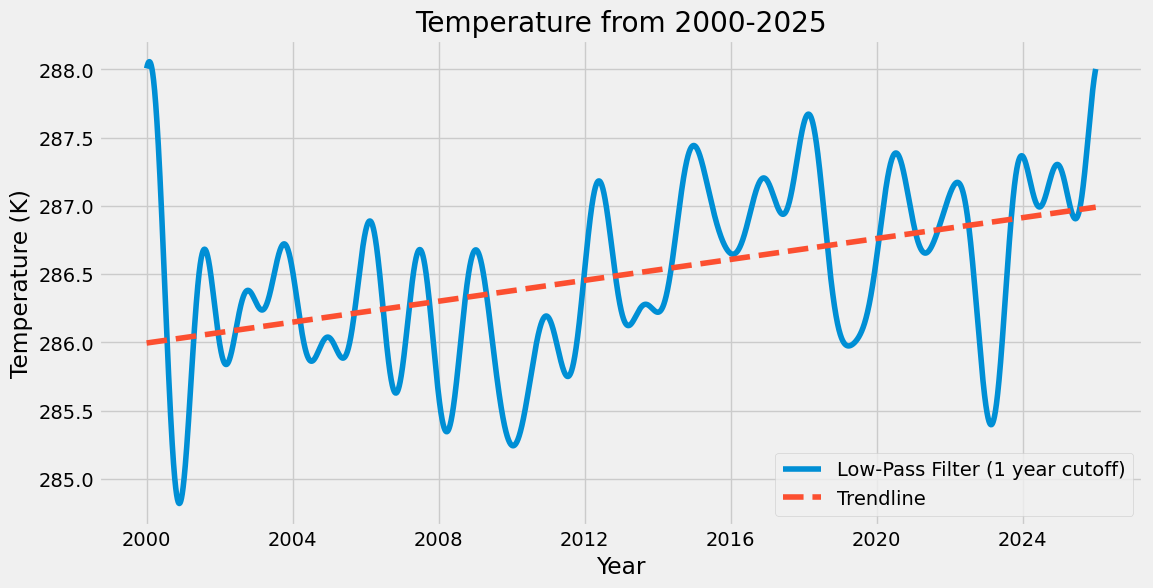

In [81]:
#fft for temperature
sr_y = 1/365.25 #sampling rate in 1/years
N = temp.size # num of measurements
temp_fft = fft(temp) #not normalized yet, fft
freqs_y = fftfreq(N, sr_y)
temp_amps = np.abs(temp_fft) #amplitude
mask = freqs_y > 0 #only possitive freqs, not including the mean

#lowpass filter
f_low = 0.9 # less than the dominant freq rn bcs its a year
lp_mask = np.abs(freqs_y) > f_low
fft_lp = temp_fft.copy()
fft_lp[lp_mask] = 0
pos_mask = freqs_y > 0

#back into the time domain :O
temp_lowpass = np.real(ifft(fft_lp))

#linear fit
coeff = np.polyfit(pd.to_numeric(dt_pe), temp_lowpass,1)
m, c = coeff
y_fit_lowpass = m*pd.to_numeric(dt_pe) + c # equaiton for the linear fit

# figure plotting lowpass filted data
fig, ax = plt.subplots(1,1,figsize=(12,6))

#lowpass filtered data with trendline
ax.plot(dt_pe, temp_lowpass,label='Low-Pass Filter (1 year cutoff)') # plotting lowpass filtered data
ax.plot(dt_pe, y_fit_lowpass, label='Trendline', ls='--') #plotting trendline for lowpass filtere data
ax.set_xlabel('Year')
ax.set_title('Temperature from 2000-2025')
ax.set_ylabel('Temperature (K)')
ax.legend()

Observing these plots, our trendlines show that there is a decrease in precipitation and evaporation, and an increase in temperature and precipitation-evaporation. The findings with temperature align with our expectations, as this indicates a rise in temperature with climate change. The trend in P-E is more surprising, as it implies that the net flux of water in the region is trending towards more water entering than exiting.

## Question 2
Are there any periodicities in surface temperature, evaporation, precipitation, and drought in the Western United States? Are these potentially related to any climate cycles (ENSO)?

In order to determine the periodicities of each of these variables, we can apply an FFT to each CSV file and create amplitude spectrums. Note that for these spectrums, we limited the x-axis to only show frequencies of 0 cycles per day to 5 cycles per day. This was done to better showcase the behavior of relatively low frequencies, which will be shown to dominate the spectra.

Largest amp: 0.0081 mm/day
Frequency associated with largest amp: 1.000 cycles per year
Period associated with largest amp: 1.000 year



(0.0, 5.0)

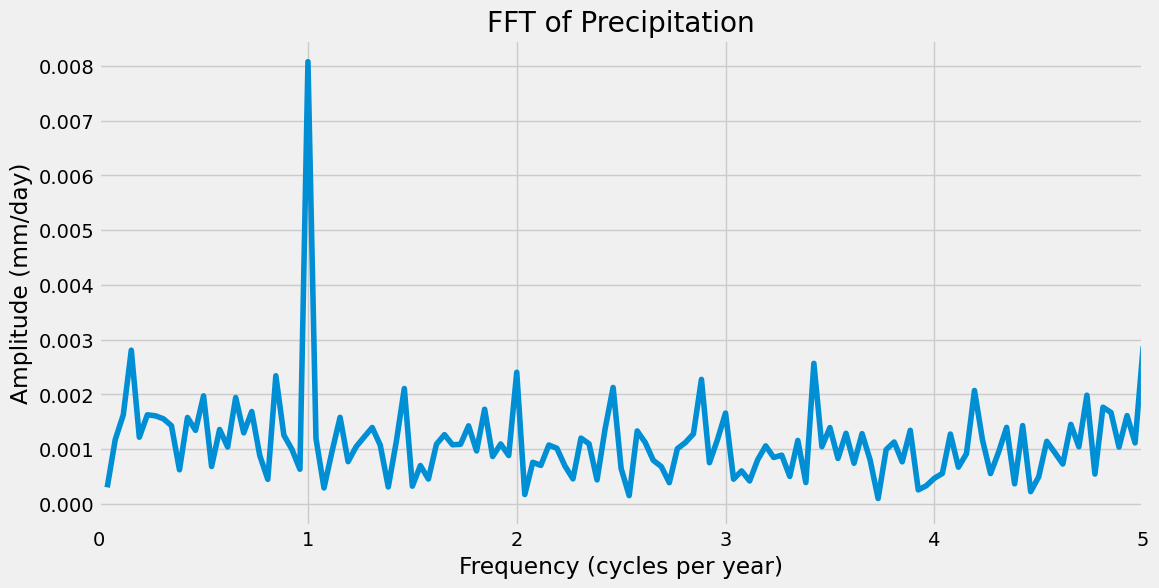

In [ ]:
#fft for precipitation
sr_y = 1/365.25 #sampling rate in 1/years
N = precip.size # num of measurements
precip_fft = fft(precip) #not normalized yet, fft
freqs_y = fftfreq(N, sr_y)
precip_amps = np.abs(precip_fft) #amplitude
mask = freqs_y > 0 #only positive freqs, not including the mean

#finding the largest amplitude
i = np.argmax(precip_amps[1:])
print(f"Largest amp: {((precip_amps[i+1]/N)):.04f} mm/day")
print(f"Frequency associated with largest amp: {freqs_y[i+1]:.03f} cycles per year")
print(f"Period associated with largest amp: {1/freqs_y[i+1]:.03f} year\n")

# figure plotting fft
fig, ax = plt.subplots(1,1,figsize=(12,6))
ax.plot(freqs_y[mask], precip_amps[mask]/N) # amplitude spectrum in cycles/year, normalized
ax.set_xlabel('Frequency (cycles per year)')
ax.set_title('FFT of Precipitation')
ax.set_ylabel('Amplitude (mm/day)')
ax.set_xlim(0,5) # Zoom into a smaller region.

For The FFT of precipitation, similar to evaporation, the dominant peak occurs near one cycle per year, indicating a strong seasonal pattern in precipitation. This reflects seasonal weather systems and climate patterns that repeat annually. The presence of smaller peaks suggests additional variability, but the annual cycle is clearly the primary driver of precipitation variability.

Largest amp: 0.0090 mm/day
Frequency associated with largest amp: 1.000 cycles per year
Period associated with largest amp: 1.000 year



(0.0, 5.0)

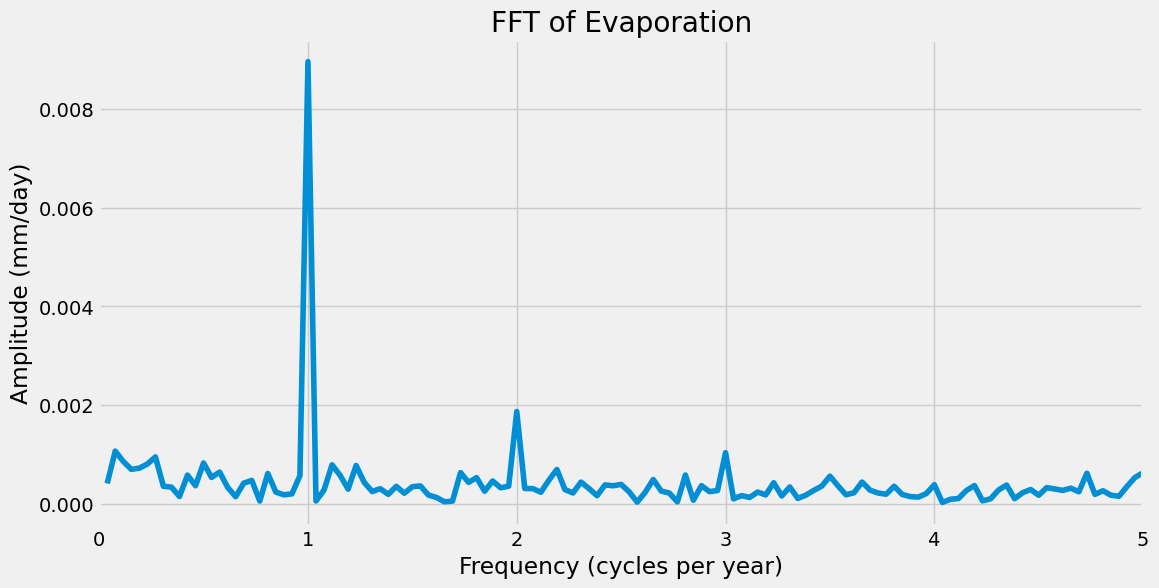

In [ ]:
#fft for evap
sr_y = 1/365.25 #sampling rate in 1/years
N = evap.size # num of measurements
evap_fft = fft(evap) #not normalized yet, fft
freqs_y = fftfreq(N, sr_y)
evap_amps = np.abs(evap_fft) #amplitude
mask = freqs_y > 0 #only positive freqs, not including the mean

#finding the largest amplitude
i = np.argmax(evap_amps[1:])
print(f"Largest amp: {(evap_amps[i+1]/N):.04f} mm/day")
print(f"Frequency associated with largest amp: {freqs_y[i+1]:.03f} cycles per year")
print(f"Period associated with largest amp: {1/freqs_y[i+1]:.03f} year\n")

#figure plotting fft
fig, ax = plt.subplots(1,1,figsize=(12,6))
ax.plot(freqs_y[mask], evap_amps[mask]/N) #amplitude spectrum in cycles/year, normalized
ax.set_xlabel('Frequency (cycles per year)')
ax.set_title('FFT of Evaporation')
ax.set_ylabel('Amplitude (mm/day)')
ax.set_xlim(0,5) # Zoom into a smaller region.

For the FFT of evaporation the figure shows the frequency spectrum of evaporation using a Fast Fourier Transform. The large peak near one cycle per year indicates a strong annual cycle in evaporation. This makes physical sense because evaporation is strongly controlled by seasonal temperature and solar radiation patterns. Smaller peaks at higher frequencies represent weaker short-term variability, but the dominant signal is clearly seasonal. 

Largest amp: 0.0165 mm/day
frequency associated with largest amp: 1.000 cycles per year
period associated with largest amp: 1.000 year



(0.0, 5.0)

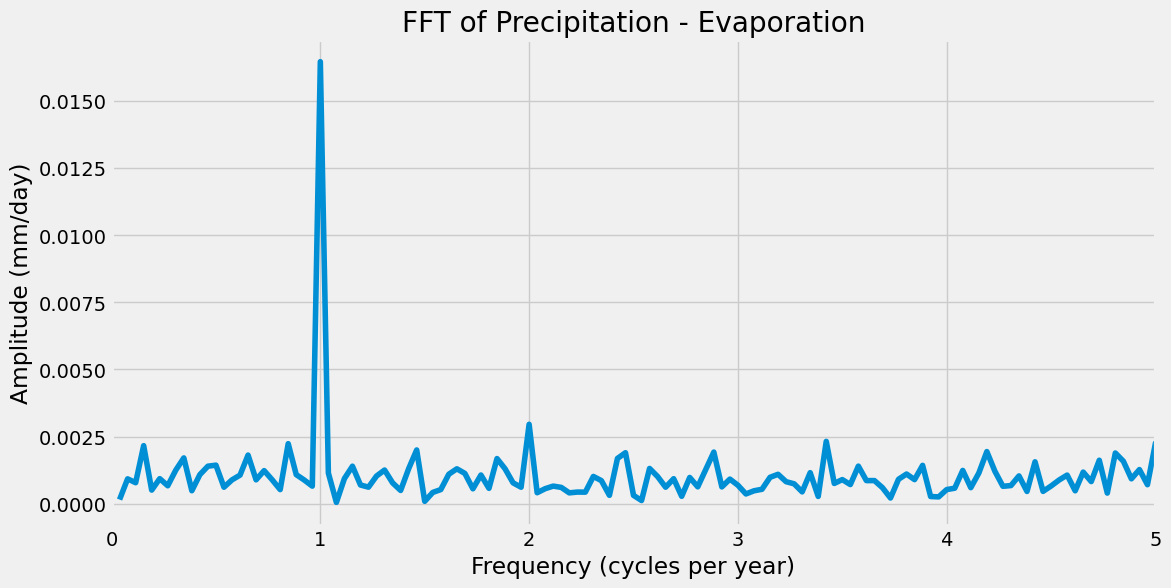

In [79]:
#fft for net precip/evap
sr_y = 1/365.25 #sampling rate in 1/years
N = net_pe.size # num of measurements
pe_fft = fft(net_pe) #not normalized yet, fft
freqs_y = fftfreq(N, sr_y) #frequency in cycles/year
pe_amps = np.abs(pe_fft) #amplitude
mask = freqs_y > 0 # making mask for only frequencies above 0 (not including the mean, same as previous fft for pdsi)

#finding the largest amplitude
i = np.argmax(pe_amps[1:])
print(f"Largest amp: {(pe_amps[i+1]/N):.04f} mm/day") #largest amp normalized
print(f"frequency associated with largest amp: {freqs_y[i+1]:.03f} cycles per year")
print(f"period associated with largest amp: {1/freqs_y[i+1]:.03f} year\n")

#creating figure for fft
fig, ax = plt.subplots(1,1,figsize=(12,6))
ax.plot(freqs_y[mask], pe_amps[mask]/N) #amplitude spectrum in cycles/year, normalized
ax.set_xlabel('Frequency (cycles per year)')
ax.set_title('FFT of Precipitation - Evaporation')
ax.set_ylabel('Amplitude (mm/day)')
ax.set_xlim(0,5)

For The FFT of P-E, the figure shows the frequency spectrum of precipitation minus evaporation, which represents the net water balance. The dominant peak again occurs near one cycle per year, indicating that seasonal patterns strongly control the balance between water input and water loss. This is important because the difference between precipitation and evaporation directly influences drought conditions and soil moisture availability. The strong annual signal suggests that seasonal climate processes are the primary driver of water balance variability.

Largest amp: 5.093 K
Frequency associated with largest amp: 1.000 cycles per year
Period associated with largest amp: 1.000 year



(0.0, 5.0)

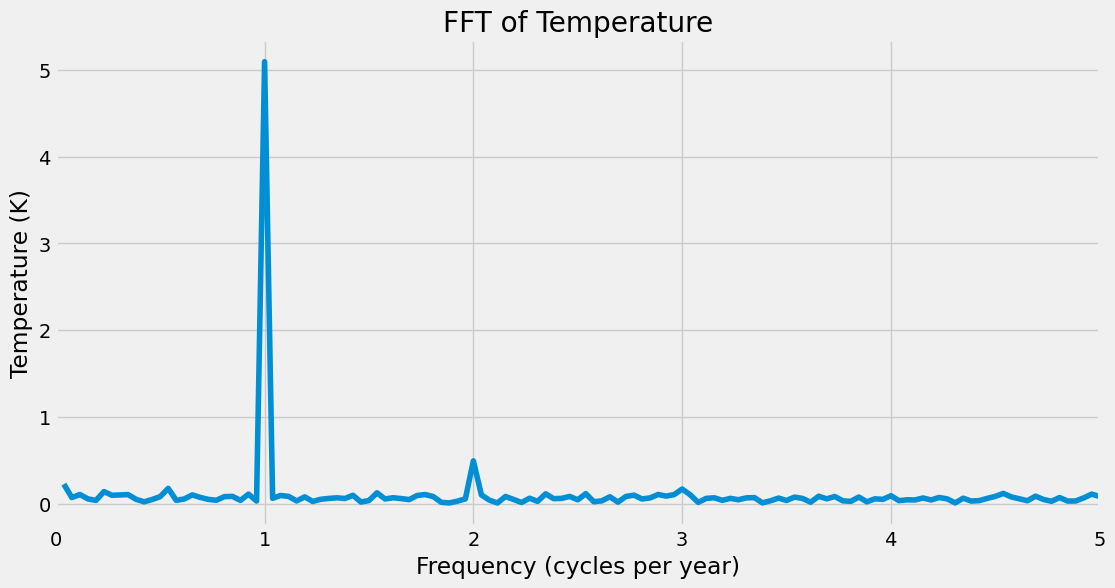

In [82]:
#fft for temperature
sr_y = 1/365.25 #sampling rate in 1/years
N = temp.size # num of measurements
temp_fft = fft(temp) #not normalized yet, fft
freqs_y = fftfreq(N, sr_y)
temp_amps = np.abs(temp_fft) #amplitude
mask = freqs_y > 0 #only possitive freqs, not including the mean

#finding the largest amplitude
i = np.argmax(temp_amps[1:])
print(f"Largest amp: {(temp_amps[i+1]/N):.03f} K")
print(f"Frequency associated with largest amp: {freqs_y[i+1]:.03f} cycles per year")
print(f"Period associated with largest amp: {1/freqs_y[i+1]:.03f} year\n")

# figure plotting fft and lowpass filted data
fig, ax = plt.subplots(1,1,figsize=(12,6))
ax.plot(freqs_y[mask], temp_amps[mask]/N) # amplitude spectrum in cycles/year, normalized
ax.set_xlabel('Frequency (cycles per year)')
ax.set_title('FFT of Temperature')
ax.set_ylabel('Temperature (K)')
ax.set_xlim(0,5)


For The FFT of temperature, the dominant peak near one cycle per year shows that temperature is strongly controlled by seasonal cycles. This is expected because temperature follows annual changes in solar radiation. Smaller peaks represent shorter-term variability, but the seasonal signal clearly dominates. Note that the dominant frequencies of the ERA5 data consistently being 1 cycle/year is the reason behind why we chose to use a low pass filter to zero out any frequencies above 0.9 cycles/year. 

Largest amp: 0.345
Frequency associated with largest amp: 0.154 cycles/year
Period associated with largest amp: 6.496 years


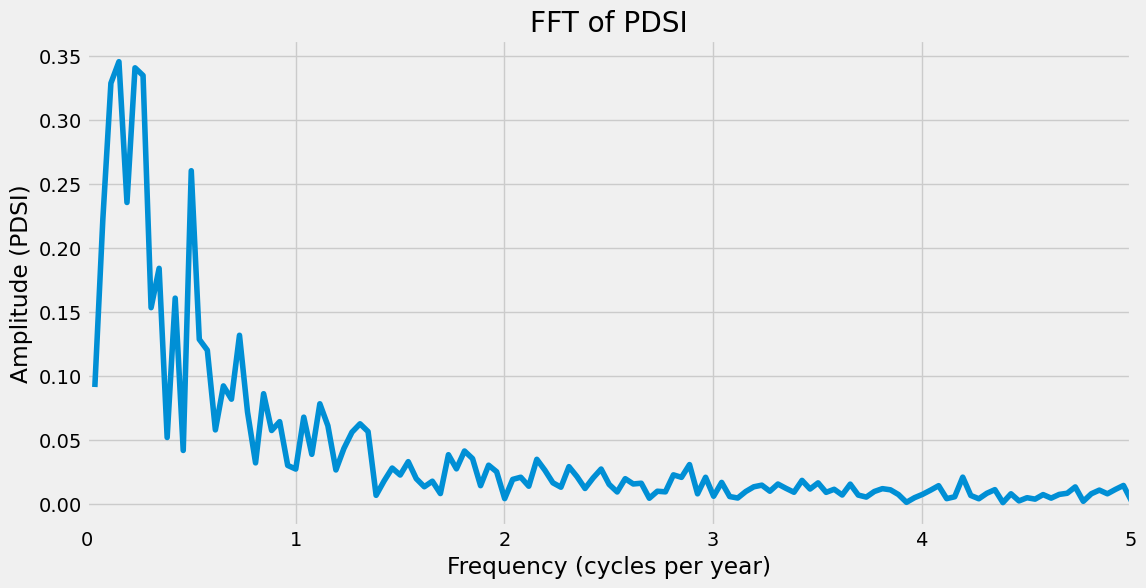

In [87]:
#fft for pdsi
sr_y = 5/365.25 #sampling rate in 1/years
N = pdsi.size # num of measurements
pdsi_fft = fft(pdsi) # fft for pdsi not normalized
freqs_y = fftfreq(N, sr_y) #frequencies for fft in years
pdsi_amps = np.abs(pdsi_fft) #amplitude
mask = freqs_y > 0 #mask to only show frequencies greater than 0 (also exclulding the mean)

#create figure and plot fft for pdsi
plt.figure(figsize=(12,6))
plt.plot(freqs_y[mask], pdsi_amps[mask]/N) #amplitude spectrum in cycles/year normalized
plt.title('FFT of PDSI')
plt.xlabel('Frequency (cycles per year)')
plt.ylabel('Amplitude (PDSI)')
plt.xlim(0,5) #setting limit to exclude frequencies above 5

#finding index of the largest amplitude
i = np.argmax(pdsi_amps[1:]) #finding largest amplitude (skipping first value because its the mean)
print(f"Largest amp: {(pdsi_amps[i+1]/N):.03f}") #printing largent amplitude *(adding 1 to index because we skipped the first value before)*
#printing the frequecy and period associated with the largest amplitude:
print(f"Frequency associated with largest amp: {freqs_y[i+1]:.03f} cycles/year")
print(f"Period associated with largest amp: {1/freqs_y[i+1]:.03f} years")


From this amplitude spectrum, we find that PDSI is dominated by a frequency corresponding to a period of 6.496 years. This aligns with what we saw earlier when we plotted PDSI as a time series. We find however that many different frequencies seem to drive PDSI, as compared to the ERA5 variables which were only dominated by annual cycles. As such, it may be helpful to analyze the periodicities of PDSI with a spectrogram as well.

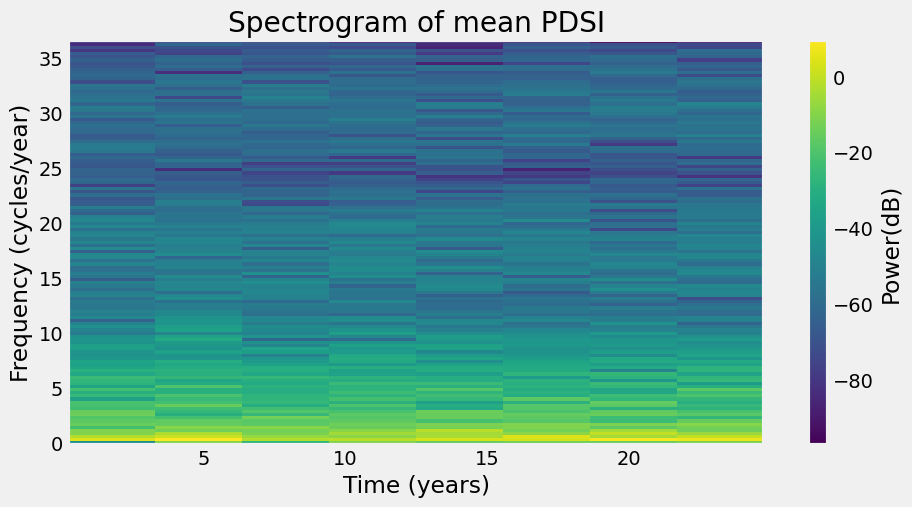

In [95]:
# Set the specs of the spectrogram
dt=5.0
fs=365.0/dt

# Create the spectrogram
f,t,Sxx=spectrogram(pdsi,fs=fs,scaling="density")

# Customize the figure
plt.figure(figsize=(10,5))
plt.pcolormesh(t,f,10*np.log10(Sxx+1e-12),shading="auto")
plt.xlabel("Time (years)")
plt.ylabel("Frequency (cycles/year)")
plt.title("Spectrogram of mean PDSI")
plt.colorbar(label="Power(dB)")
plt.show()

The spectrogram we had shows how the strength of drought variability changes across different frequencies over time. Most of the signal power is concentrated at low frequencies, which indicates that long-term climate variability dominates the PDSI signal rather than short-term fluctuations. Given that PDSI is driven by long-term climate variabilities, we thought it may be insightful to analyze PDSI in tandem with ENSO, which is itself a long-term climate cycle that can affect the Southwest US.

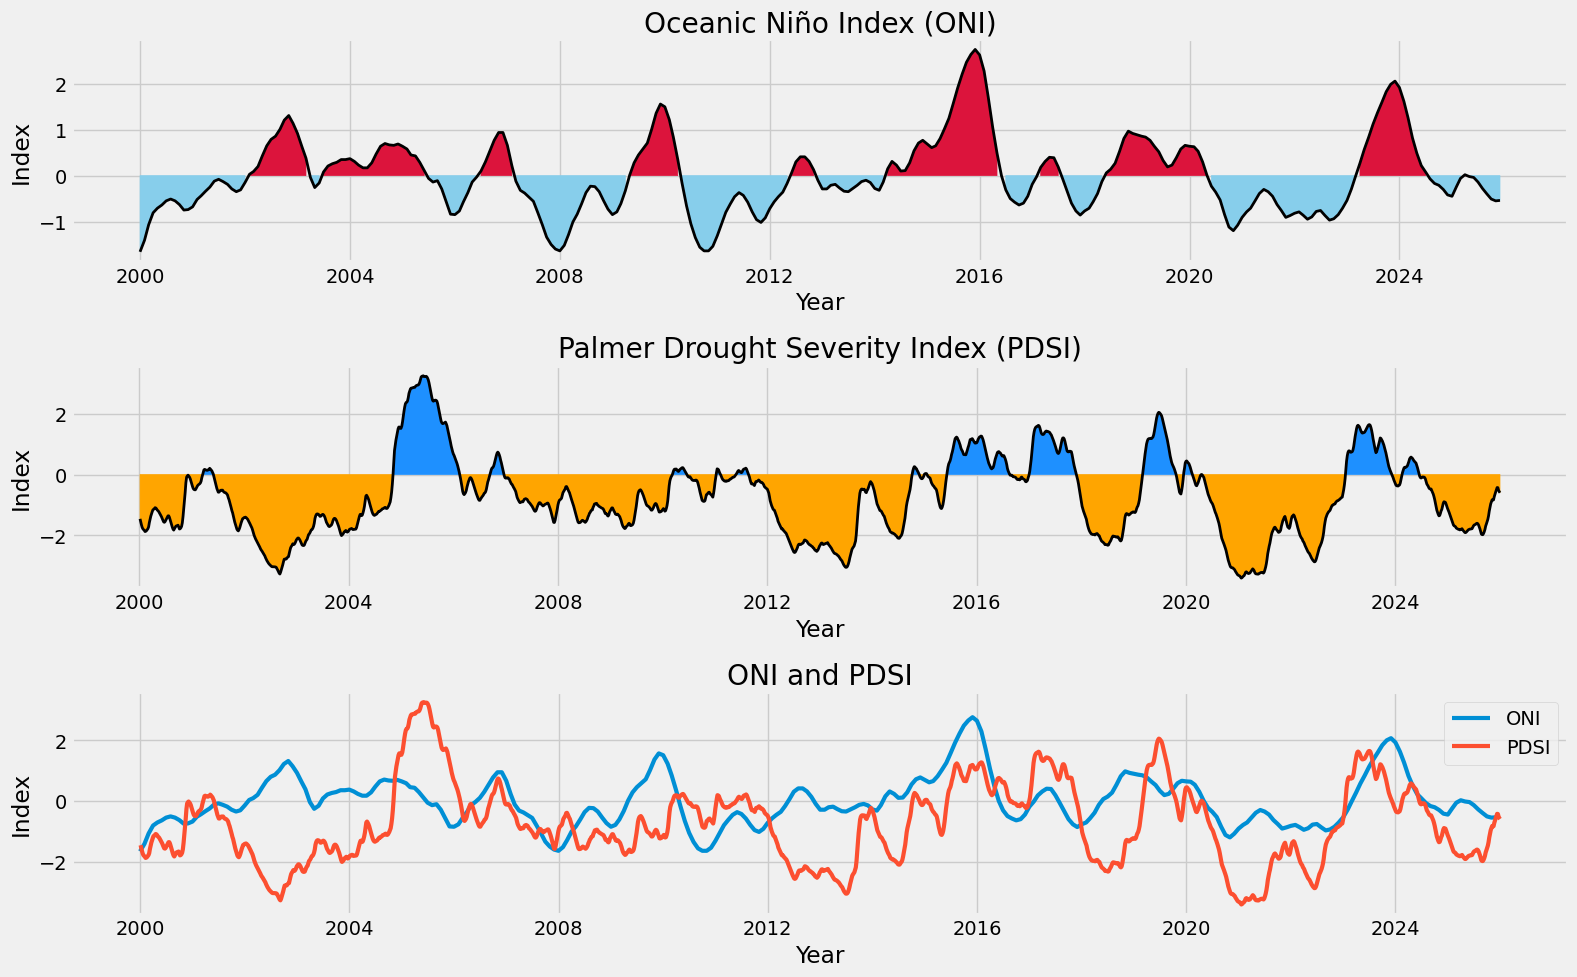

In [89]:
#reading in ENSO stuff
#comparing pdsi and enso
data = np.genfromtxt("enso_ONI.txt",skip_header=1,  dtype=None, names=('seas', 'year', 'total', 'anamoly'), encoding="utf-8")
oni = data['anamoly']
dt_oni = np.arange('2000-01-01', '2026-01-01', dtype='datetime64[M]') #creating a datetime array for the time, monthly measurements

fig, ax = plt.subplots(3,1,figsize=(16,10)) # creating figure to plot ONI, PDSI, and both

#plotting oni
ax[0].plot(dt_oni, oni, color='black', lw=2)
ax[0].set_title('Oceanic Niño Index (ONI)')
ax[0].set_ylabel('Index')
ax[0].set_xlabel('Year')

#FILLING INNNN (making positive values red and negative values blue)
pos = np.where(oni >0, oni, np.nan)
neg = np.where(oni < 0, oni, np.nan)
ax[0].fill_between(dt_oni, 0, pos, color='crimson')
ax[0].fill_between(dt_oni, 0, neg, color='skyblue')
#plotting pdsi
ax[1].plot(pd.to_datetime(time_pdsi), pdsi, color='black', lw=2)
ax[1].set_title('Palmer Drought Severity Index (PDSI)')
ax[1].set_ylabel('Index')
ax[1].set_xlabel('Year')
#making positive values blue and negative values orange
pos = np.where(pdsi > 0, pdsi, np.nan)
neg = np.where(pdsi < 0, pdsi, np.nan)
ax[1].fill_between(pd.to_datetime(time_pdsi), 0, pos, color='dodgerblue')
ax[1].fill_between(pd.to_datetime(time_pdsi), 0, neg, color='orange')

#plotting oni and pdsi on the same plot
ax[2].plot(dt_oni, oni, label='ONI', lw=3)
ax[2].plot(pd.to_datetime(time_pdsi), pdsi, label='PDSI', lw=3)
ax[2].set_title('ONI and PDSI')
ax[2].set_ylabel('Index')
ax[2].set_xlabel('Year')
ax[2].legend()
plt.tight_layout()


ENSO affects the amount of precipitation in the Western US, which is why we chose to investigate this. We compared the Oceanic Niño Index (ONI) with PDSI. ONI values above +0.5 are associated with El Niño, and values below -0.5 are associated with La Niña. We expected positive ONI values to correspond to negative PDSI values because El Niño is associated with drier conditions in the western US. From plotting time series of both datasets, we did not discover any noticeable correlations between the 2 indices for this time period. Because of this, we chose to not further investigate ENSO’s correlation to PDSI and focus on our other variables.

## Question 3
Are there spatial and temporal correlations between surface temperature, evaporation, precipitation, and drought in the Western United States? 

Now that we've examined the trends and periodicities of each variable separately, we can return to our original overarching question of what drives drought in the Southwest US. To do this, we can employ two different methods. The first of which is spatial correlation between the different gridded netCDF datasets, and the second being temporal correlation between PDSI and the low-passed filtered data. We can do the first using xarray's corr function, which finds the spatial correlation between two different xarray DataArrays [12]. Note that in order for this to work, we need both xarrays to have the same dimensions. If you noticed earlier during the data processing, PDSI has a much finer spatial resolution than the ERA5 data. Thus, we'll employ the xesmf regridder, which can regrid the PDSI data to match the resolution of the ERA5 data [13]. 

When finding the correlation between PDSI and some ERA5 variable, we may find an unexpectedly low correlation as a result of the two variable's different periodicities. As discussed before, PDSI has a periodcity of around 6-7 years, whereas every ERA5 variable is driven by annual cycles. Thus, it may be more helpful to find the correlation between PDSI and a variable's anomaly. We define anomaly as the the difference of some day of data from the climatatology. For example, the anomaly for January 5, 2000's temperature would be said temperature minus the mean of all Janurary 5's temperature for every year. The code used to calculate this anomaly was guided by a GitHub document by Ryan Abernathey. This document also highlights the importance of the dask library, which can be used to optimize the runtime and memory handling of our code [14].

In [ ]:
# Standardize every dataset to make a universal function possible.
# Rename the variables in each dataset.
ds_pdsi = ds_pdsi.rename({'day':'time'})
ds_pdsi = ds_pdsi.rename({'daily_mean_palmer_drought_severity_index':'PDSI'})
ds_temp = ds_temp.rename({'valid_time':'time'})
ds_evap = ds_evap.rename({'valid_time':'time'})
ds_prec = ds_prec.rename({'valid_time':'time'})

# Open the xarray DataArrays (needed for correlation).
# Chunk the DataArrays to handle later memory issues.
pdsi = ds_pdsi['PDSI']
pdsi = pdsi.chunk({"time": 100})
temp = ds_temp['t2m']
temp = temp.chunk({"time": 100})
evap = ds_evap['e']
evap = evap.chunk({"time": 100})
evap = -1*evap # Convert to positive.
prec = ds_prec['tp']
prec = prec.chunk({"time": 100})
PminE = prec - evap
PminE.name = 'pe'

In [ ]:
def PDSIcorrMap(ds, dataArray, anomaly=True):
    if anomaly:
        # Calculate the anomaly.
        gb = dataArray.groupby('time.dayofyear')
        anom = dataArray.groupby('time.dayofyear') - gb.mean(dim='time')

    # Regrid the PDSI data to fit the temperature data.
    regridder = xe.Regridder(ds_pdsi, ds, "bilinear")
    pdsi_regridded = regridder(pdsi, keep_attrs=True)

    # Align the two datasets for correlation.
    # Should handle the different temporal resolutions.
    if anomaly: 
        anom, pdsi_regridded = xr.align(anom, pdsi_regridded, join='inner')
        # Create an xarray of correlations.
        spatial_corr = xr.corr(anom, pdsi_regridded, dim='time')
        # Save as a netcdf file.
        spatial_corr.rename("correlation").to_netcdf(f"{dataArray.name}_anom2pdsi.nc")
    else: 
        dataArray, pdsi_regridded = xr.align(dataArray, pdsi_regridded, join='inner')
        # Create an xarray of correlations.
        spatial_corr = xr.corr(dataArray, pdsi_regridded, dim='time')
        # Save as a netcdf file.
        spatial_corr.rename("correlation").to_netcdf(f"{dataArray.name}2pdsi.nc")

In [ ]:
# Create the correlation map netcdf files.
# NOTE! Do not run if you already have these files created.
PDSIcorrMap(ds_temp, temp, anomaly=False)
PDSIcorrMap(ds_temp, temp, anomaly=True)
PDSIcorrMap(ds_evap, evap, anomaly=False)
PDSIcorrMap(ds_evap, evap, anomaly=True)
PDSIcorrMap(ds_prec, prec, anomaly=False)
PDSIcorrMap(ds_prec, prec, anomaly=True)
PDSIcorrMap(ds_prec, PminE, anomaly=False)
PDSIcorrMap(ds_prec, PminE, anomaly=True)

In [97]:
# Change style back to default.
plt.style.use('default')

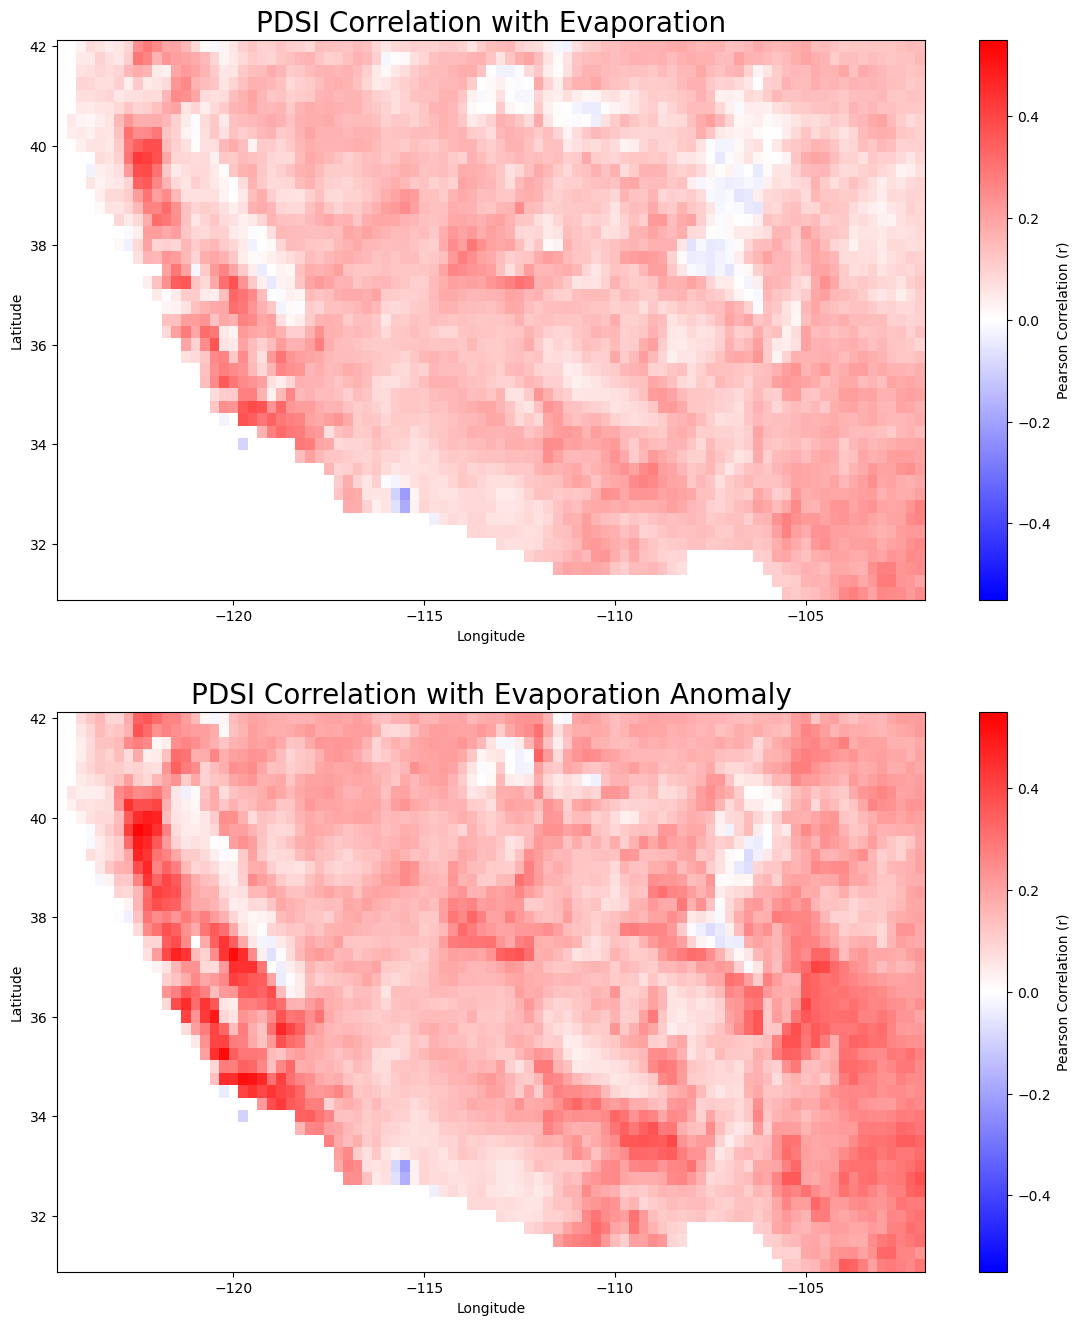

In [99]:
# Create the evaporation spatial correlation plots.
# Open the new netcdf file.
ds_corr1 = xr.open_dataset('e2pdsi.nc')
ds_corr2 = xr.open_dataset('e_anom2pdsi.nc')

# Turn the xarray datasets into DataArrays
corr_map1 = ds_corr1["correlation"]
corr_map2 = ds_corr2["correlation"]

# Create a figure and axis.
fig, (ax1, ax2) = plt.subplots(2, 1, figsize = [14,16])

# Plot the data.
corr_map1.plot(cmap="bwr", ax=ax1, vmin = -0.55, vmax = 0.55, 
               cbar_kwargs={'label': 'Pearson Correlation (r)'})
corr_map2.plot(cmap="bwr", ax=ax2, vmin = -0.55, vmax = 0.55, 
               cbar_kwargs={'label': 'Pearson Correlation (r)'})

# Label the plot.
ax1.set_title('PDSI Correlation with Evaporation', fontsize=20)
ax1.set_xlabel('Longitude')
ax1.set_ylabel('Latitude')
ax2.set_title('PDSI Correlation with Evaporation Anomaly', fontsize=20)
ax2.set_xlabel('Longitude')
ax2.set_ylabel('Latitude')

# Close the datasets.
ds_corr1.close()
ds_corr2.close()

We find that there is a relative strong (as compared to the plots below) positive correlation between PDSI and evaporation. This correlation is notably stronger between PDSI and evaporation anomaly, implying that our inital theory that removing the ERA5 annual periodicity could help strengthen correlations. This correlation is especially strong in Calfornia, and seems to follow geographic features. A strong correlation between the two indicates that wetter periods correspond with higher evaporation. This implies that despite evaporation removing water from the land, we find that more evaporation means more water. We can explain this unexpected finding with the logic that the wetter the region, the more water available to evaporate. 

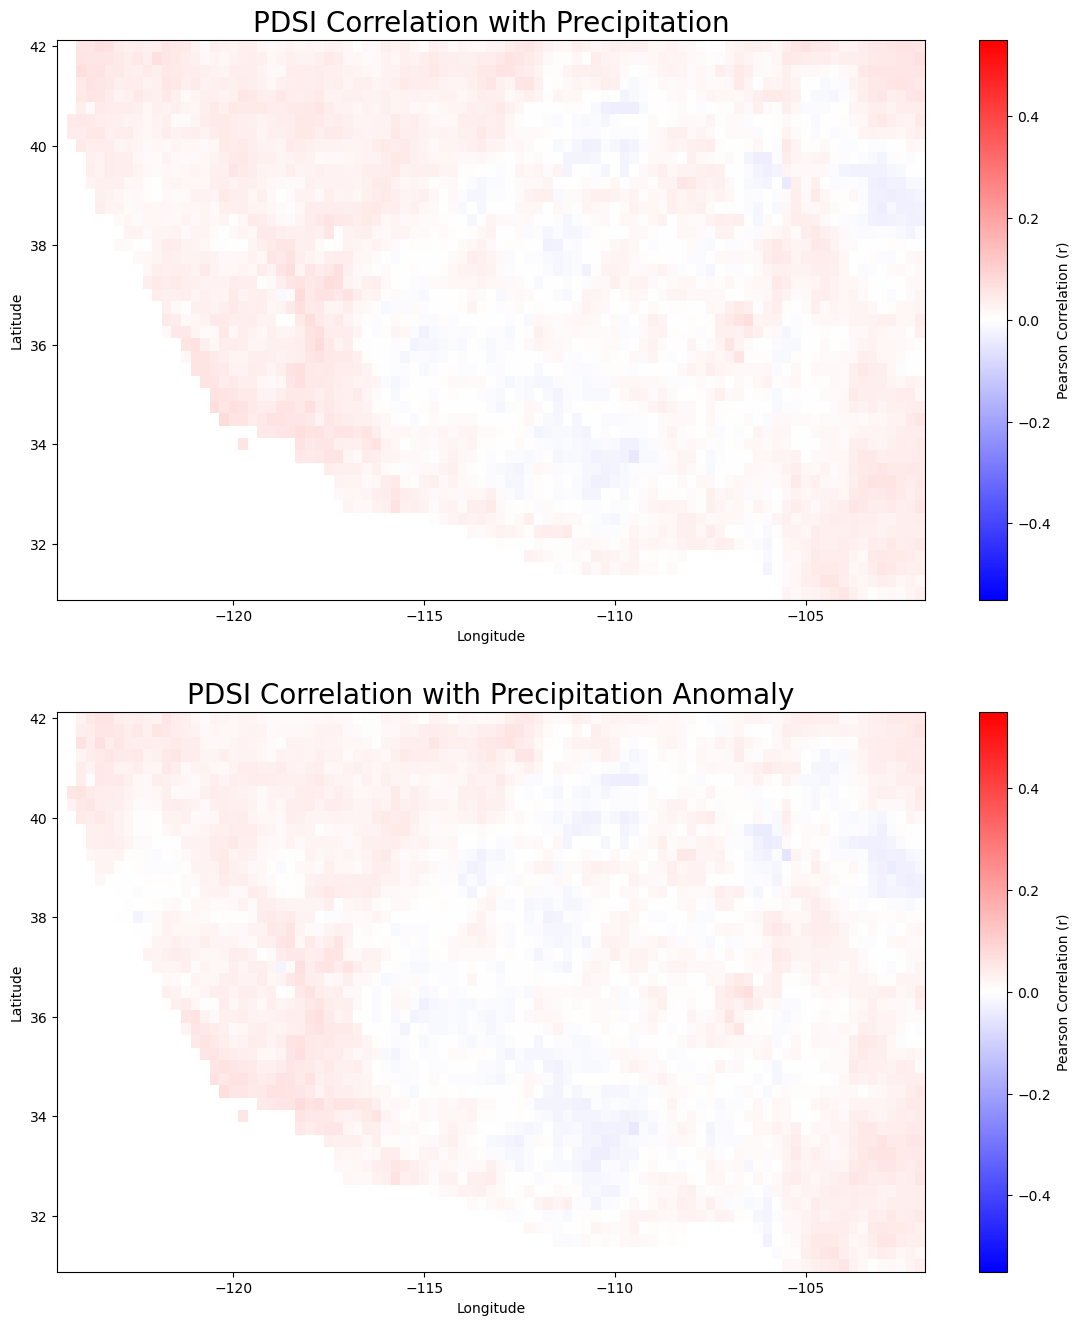

In [100]:
# Create the precipitation spatial correlation plots.
# Open the new netcdf file.
ds_corr1 = xr.open_dataset('tp2pdsi.nc')
ds_corr2 = xr.open_dataset('tp_anom2pdsi.nc')

# Turn the xarray datasets into DataArrays
corr_map1 = ds_corr1["correlation"]
corr_map2 = ds_corr2["correlation"]

# Create a figure and axis.
fig, (ax1, ax2) = plt.subplots(2, 1, figsize = [14,16])

# Plot the data.
corr_map1.plot(cmap="bwr", ax=ax1, vmin = -0.55, vmax = 0.55, 
               cbar_kwargs={'label': 'Pearson Correlation (r)'})
corr_map2.plot(cmap="bwr", ax=ax2, vmin = -0.55, vmax = 0.55, 
               cbar_kwargs={'label': 'Pearson Correlation (r)'})

# Label the plot.
ax1.set_title('PDSI Correlation with Precipitation', fontsize=20)
ax1.set_xlabel('Longitude')
ax1.set_ylabel('Latitude')
ax2.set_title('PDSI Correlation with Precipitation Anomaly', fontsize=20)
ax2.set_xlabel('Longitude')
ax2.set_ylabel('Latitude')

# Close the datasets.
ds_corr1.close()
ds_corr2.close()

We find that there appears to be no correlation between PDSI and precipitation, even when plotting against precipitation anomaly. This is an especially surprising result, as one would think that incoming water would affect drought. This result could likely be explained by the fact that precipitation is mostly zero on most days in most regions, whereas PDSI is always changing. Additionally, how much it rained one day in region might not affect the long term dryness of the region, which is what drought is. We see then that the factors behind PDSI, and in turn drought, are far more complex than what we initially thought.

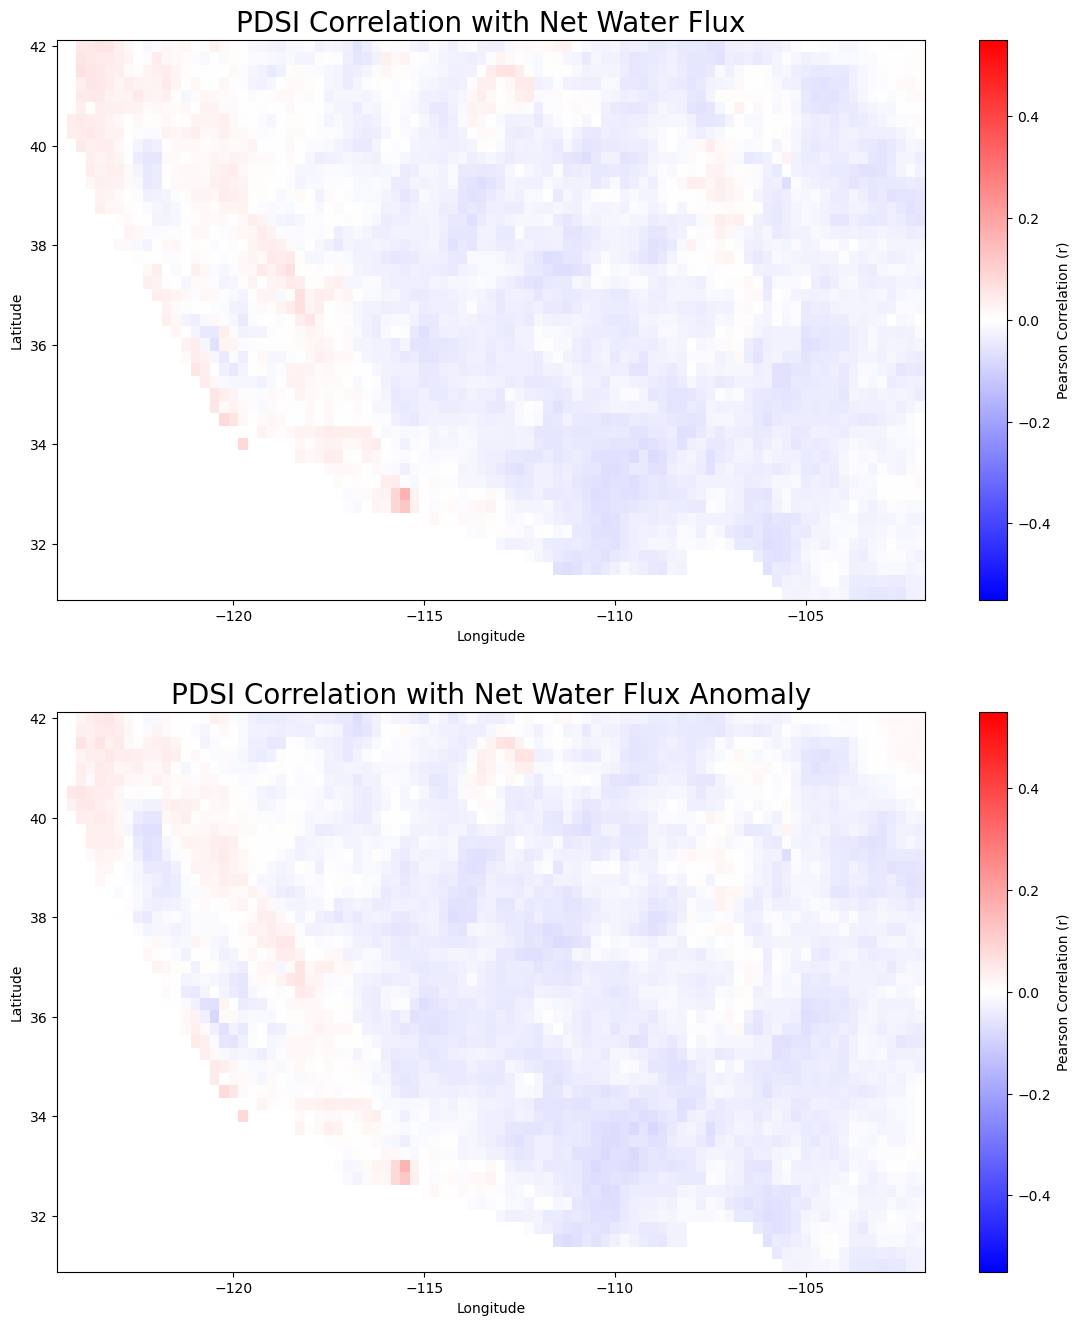

In [101]:
# Create the P-E spatial correlation plots.
# Open the new netcdf file.
ds_corr1 = xr.open_dataset('pe2pdsi.nc')
ds_corr2 = xr.open_dataset('pe_anom2pdsi.nc')

# Turn the xarray datasets into DataArrays
corr_map1 = ds_corr1["correlation"]
corr_map2 = ds_corr2["correlation"]

# Create a figure and axis.
fig, (ax1, ax2) = plt.subplots(2, 1, figsize = [14,16])

# Plot the data.
corr_map1.plot(cmap="bwr", ax=ax1, vmin = -0.55, vmax = 0.55, 
               cbar_kwargs={'label': 'Pearson Correlation (r)'})
corr_map2.plot(cmap="bwr", ax=ax2, vmin = -0.55, vmax = 0.55, 
               cbar_kwargs={'label': 'Pearson Correlation (r)'})

# Label the plot.
ax1.set_title('PDSI Correlation with Net Water Flux', fontsize=20)
ax1.set_xlabel('Longitude')
ax1.set_ylabel('Latitude')
ax2.set_title('PDSI Correlation with Net Water Flux Anomaly', fontsize=20)
ax2.set_xlabel('Longitude')
ax2.set_ylabel('Latitude')

# Close the datasets.
ds_corr1.close()
ds_corr2.close()

The plot above indicates a weak negative correlation between PDSI and net water flux. This is likely just a result of precipiation having such a low correlation with PDSI. Thus, we can gather no meaningful conclusion from this plot other than that drought is a complex phenomema.

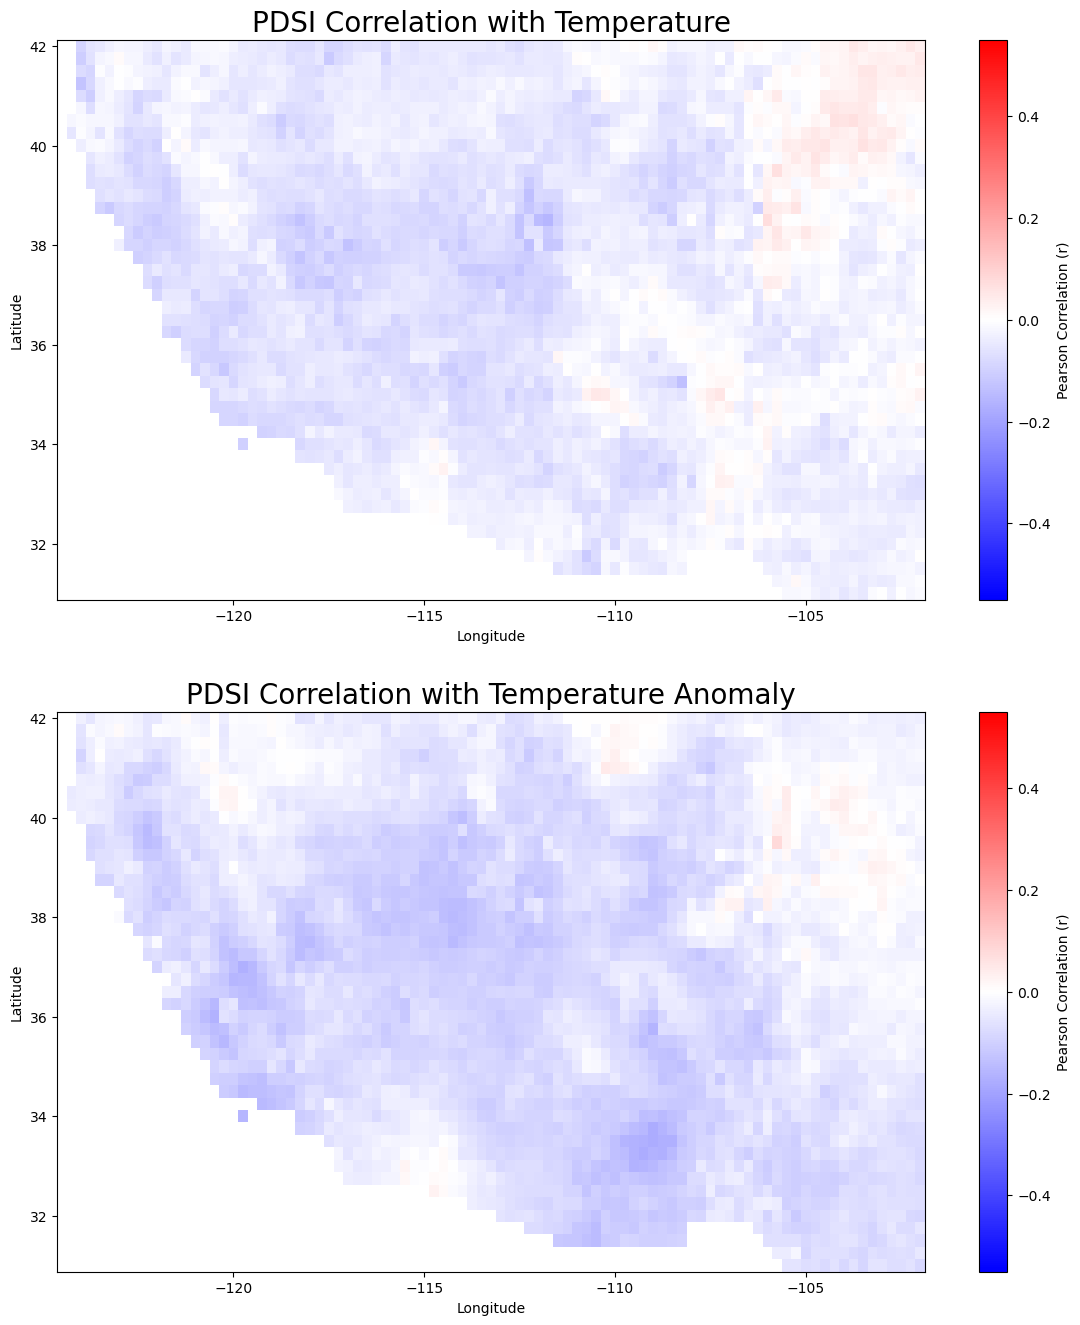

In [ ]:
# Create the temperature spatial correlation plots.
# Open the new netcdf file.
ds_corr1 = xr.open_dataset('t2m2pdsi.nc')
ds_corr2 = xr.open_dataset('t2m_anom2pdsi.nc')

# Turn the xarray datasets into DataArrays
corr_map1 = ds_corr1["correlation"]
corr_map2 = ds_corr2["correlation"]

# Create a figure and axis.
fig, (ax1, ax2) = plt.subplots(2, 1, figsize = [14,16])

# Plot the data.
corr_map1.plot(cmap="bwr", ax=ax1, vmin = -0.55, vmax = 0.55, 
               cbar_kwargs={'label': 'Pearson Correlation (r)'})
corr_map2.plot(cmap="bwr", ax=ax2, vmin = -0.55, vmax = 0.55, 
               cbar_kwargs={'label': 'Pearson Correlation (r)'})

# Label the plots.
ax1.set_title('PDSI Correlation with Temperature', fontsize=20)
ax1.set_xlabel('Longitude')
ax1.set_ylabel('Latitude')
ax2.set_title('PDSI Correlation with Temperature Anomaly', fontsize=20)
ax2.set_xlabel('Longitude')
ax2.set_ylabel('Latitude')

# Close the datasets.
ds_corr1.close()
ds_corr2.close()

We find that PDSI has a weak negative correlation with surface temperature. However, this correlation is still stronger than that with precipitation, which aligns with our background literature. This weak correlation implies that drier periods are generally warmer periods in the Southwest US.

Ultimately we found that via the spatial correlation method, we couldn't find much correlation between PDSI and any of our ERA5 variables. The strongest correlation only had a max R value of around 0.45. As we touched on earlier, this is likely a result of trying to correlate PDSI, a variable with a long term cycle, with variables that are driven by annual changes. As such, we could try to instead find the correlation between PDSI and the low-passed filtered data we created for Question 1. With this correlation, we can only find the temporal correlation, as completing the spatial correlation with low-passed filtered data requires complex code and data processing beyond the scope of this project. Note that in order to find tis temporal correlation, we need to make sure that both datasets have the same temporal resolution.

For Temperature and PDSI:
The Pearson Correlation Coefficient is -0.1394
The Coefficient of Determination is 0.0194

For Precipitaiton and PDSI:
The Pearson Correlation Coefficient is 0.4985
The Coefficient of Determination is 0.2485

For Evaporation:
The Pearson Correlation Coefficient is 0.6407
The Coefficient of Determination is 0.4105

For Precipitation - Evaporation:
The Pearson Correlation Coefficient is 0.3160
The Coefficient of Determination is 0.0999


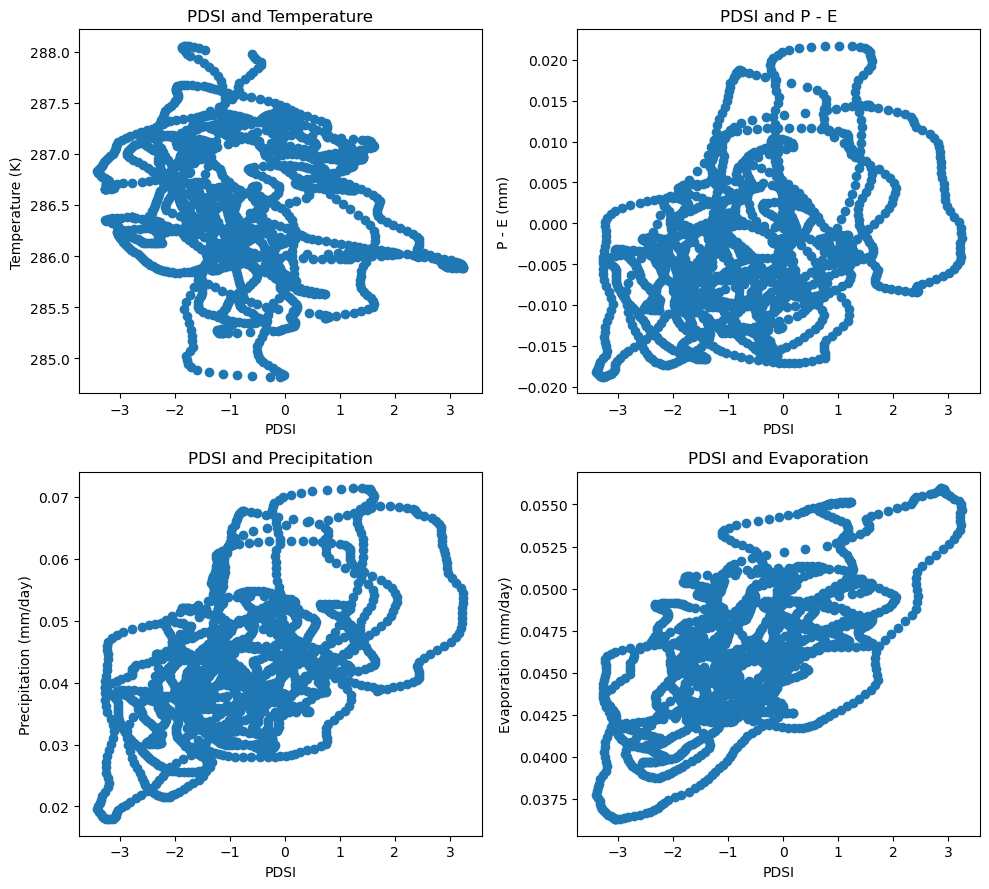

In [105]:
# Crop the era 5 data so that it has the same number of points as PDSI
temp_cropped = temp_lowpass[4:] #skipping first days to start on Jan 5 2000 like pdsi data does
temp_cropped = temp_cropped[::5] #skipping every 5 days like the pdsi data does
temp_cropped = temp_cropped[0:1898] #it was one point too long so we're just going to get rid of the last point

#repeating for pe, e, and p...
pe_cropped =pe_lowpass[4:]
pe_cropped = pe_cropped[::5]
pe_cropped = pe_cropped[0:1898]

e_cropped =evap_lowpass[4:]
e_cropped = e_cropped[::5]
e_cropped = e_cropped[0:1898]

p_cropped =precip_lowpass[4:]
p_cropped = p_cropped[::5]
p_cropped = p_cropped[0:1898]

# Create the correlation coefficient matrix.
cc = np.corrcoef(pdsi, temp_cropped)
# Extract the Pearson Correlation Coefficient.
r = cc[0, 1]
# Calculate the Coefficient of Determination.
r_sq = r**2
# Print the results.
print(f'For Temperature and PDSI:\nThe Pearson Correlation Coefficient is {r:.4f}')
print(f'The Coefficient of Determination is {r_sq:.4f}\n')


# Create the correlation coefficient matrix.
cc = np.corrcoef(pdsi, p_cropped)
# Extract the Pearson Correlation Coefficient.
r = cc[0, 1]
# Calculate the Coefficient of Determination.
r_sq = r**2
# Print the results.
print(f'For Precipitaiton and PDSI:\nThe Pearson Correlation Coefficient is {r:.4f}')
print(f'The Coefficient of Determination is {r_sq:.4f}\n')


# Create the correlation coefficient matrix.
cc = np.corrcoef(pdsi, e_cropped)
# Extract the Pearson Correlation Coefficient.
r = cc[0, 1]
# Calculate the Coefficient of Determination.
r_sq = r**2
# Print the results.
print(f'For Evaporation:\nThe Pearson Correlation Coefficient is {r:.4f}')
print(f'The Coefficient of Determination is {r_sq:.4f}\n')

# Create the correlation coefficient matrix.
cc = np.corrcoef(pdsi, pe_cropped)

# Extract the Pearson Correlation Coefficient.
r = cc[0, 1]
# Calculate the Coefficient of Determination.
r_sq = r**2

# Print the results.
print(f'For Precipitation - Evaporation:\nThe Pearson Correlation Coefficient is {r:.4f}')
print(f'The Coefficient of Determination is {r_sq:.4f}')

#plotting the datasets against eachother for funsies/ to visually see the correlation (or lack there of)

fig, ax = plt.subplots(2,2,figsize=(10,9))

ax[0,0].scatter(pdsi, temp_cropped)
ax[0,0].set_title('PDSI and Temperature')
ax[0,0].set_xlabel('PDSI')
ax[0,0].set_ylabel('Temperature (K)')

ax[0,1].scatter(pdsi, pe_cropped)
ax[0,1].set_title('PDSI and P - E')
ax[0,1].set_xlabel('PDSI')
ax[0,1].set_ylabel('P - E (mm)')

ax[1,0].scatter(pdsi, p_cropped)
ax[1,0].set_title('PDSI and Precipitation')
ax[1,0].set_xlabel('PDSI')
ax[1,0].set_ylabel('Precipitation (mm/day)')

ax[1,1].scatter(pdsi, e_cropped)
ax[1,1].set_title('PDSI and Evaporation')
ax[1,1].set_xlabel('PDSI')
ax[1,1].set_ylabel('Evaporation (mm/day)')

plt.tight_layout()


From these plots and our calculations, we find that once again, evaporation has the strongest correlation with PDSI. We can explain this with the same reasoning as before. Interestingly, precipitation and P-E now see much higher correlations, with them being positive as well. This aligns much more closely with our expectations. The more water entering the region in a given period, the wetter that period should be. Temperature now stands as the variable with the lowest correlation with PDSI, which goes against our initial research. This finding is likely a result of different methodologies between our work and NOAA's study.

----

## Conclusion
&emsp;To conclude, our research narrowed in on data surrounding drought in the southwestern region of the United States. We processed our data through fast fourier transforms, low pass filters to find trends, compared it to the ENSO indices, and examined spatial correlations to better understand how precipitation, evaporation, and temperature have changed in the last 25 years and how it corresponds to the PDSI. Through our findings, we found that the most prominent factor contributing to drought conditions in the area was in fact temperature. 
Temperature is steadily increasing, and this rise is dramatically displayed over the course of the last two decades. 

&emsp;Our analysis validates the study conducted by NOAA. When analyzing their spatial correlation, warmer temperatures are in fact to blame for the extreme and exceptional drought in the Western states. Precipitation levels, as seen graphically through our plots, are not as significant as a contributing factor. We do note that is not the case when comparing low-passed filtered precipitation to PDSI. This could possibly just be a result of the differences in our methodology. Interestingly, we found that it was neither temperature nor precipitation that was most correlation with drought, but instead evaporation. 
Overall, we know that climate change will directly cause temperatures to continue to rise. With that being said, drought conditions will continue to worsen if steps are not taken to mitigate the warming impacts. Marginalized and indigenous communities in the Western United States will unfortunately face water insecurity first. [3] Our research is just a starting point and we hope that it can be used to properly deal with the drought crisis. 


----

## References
[1] “The Western Drought Issue | September 3, 2025 | Drought.gov,” Drought.gov, Sep. 03, 2025. https://www.drought.gov/news/western-drought-issue-2025-09-03

‌[2] NDMC, “How Does Drought Affect Our Lives?,” Unl.edu, 2019. https://drought.unl.edu/Education/DroughtforKids/DroughtEffects.aspx

[3] C. Greene and D. B. Ferguson, “Equity, Justice, and Drought: Lessons for Climate Services from the U.S. Southwest,” Bulletin of the American Meteorological Society, vol. 105, no. 1, pp. E45–E58, Jan. 2024, doi: https://doi.org/10.1175/bams-d-22-0185.1.

[4] NCAR, “Palmer Drought Severity Index (PDSI) | NCAR - Climate Data Guide,” climatedataguide.ucar.edu. https://climatedataguide.ucar.edu/climate-data/palmer-drought-severity-index-pdsi

‌[5] T. Stein, “Study: heat, not lack of precipitation, is driving western U.S. droughts - NOAA Research,” NOAA Research, Nov. 08, 2024. https://research.noaa.gov/new-study-finds-heat-not-lack-of-precipitation-is-driving-western-u-s-droughts/

[6] ECMWF, “ERA5 post-processed daily statistics on single levels from 1940 to present,” Copernicus.eu, Oct. 2024, doi: https://doi.org/10.24381/cds.4991cf48.

[7] “U.S. Gridded Palmer Drought Severity Index (PDSI) from gridMET | Drought.gov,” www.drought.gov. https://www.drought.gov/data-maps-tools/us-gridded-palmer-drought-severity-index-pdsi-gridmet‌

[8] NOAA, “Current Monthly Atmospheric and Sea Surface Temperatures Index Values,” www.cpc.ncep.noaa.gov. https://www.cpc.ncep.noaa.gov/data/indices/ (accessed Apr. 20, 2026).

[9] R. Lindsey, “Climate Variability: Oceanic Niño Index | NOAA Climate.gov,” www.climate.gov, Aug. 30, 2009. https://www.climate.gov/news-features/understanding-climate/climate-variability-oceanic-nino-index

[10] N. Nayak, “Combine many netCDF files into a single file with Python,” Medium, Jun. 01, 2020. https://neetinayak.medium.com/combine-many-netcdf-files-into-a-single-file-with-python-469ba476fc14 (accessed Apr. 20, 2026).

[11] xarray Developers, “xarray.DataArray.mean,” xarray, Apr. 13, 2026. https://docs.xarray.dev/en/stable/generated/xarray.DataArray.mean.html (accessed Apr. 20, 2026).

[12] xarray Developers, “xarray.corr,” xarray, May 13, 2024. https://docs.xarray.dev/en/v2024.05.0/generated/xarray.corr.html (accessed Apr. 20, 2026).

[13] J. Zhuang and xESMF development team, “xESMF: Universal Regridder for Geospatial Data — xESMF 0.9.3.dev0+g0ca1ab1a3.d20251127 documentation,” Readthedocs.io, 2025. https://xesmf.readthedocs.io/en/stable/

[14] Ryan Abernathey, “Xarray Anomaly Calculations,” Gist, Nov. 27, 2019. https://gist.github.com/rabernat/30e7b747f0e3583b5b776e4093266114 (accessed Apr. 20, 2026).